# CMPS 364 – Advanced Machine Learning
## Assignment 4, Part II: Open-Set Face Recognition

You build the recognition engine of a building entrance: the door must open for enrolled members and stay closed for everybody else. You train Siamese networks with the triplet loss and a DeepFace-style pair classifier, implement the evaluation metrics yourself, and measure how the system behaves with people it has never seen, with degraded photos, and when genuine attempts are rare.

**Data.** Labeled Faces in the Wild (LFW), loaded with scikit-learn. Train, validation and test contain different people (Part 1).

**How to work through this notebook**
- Cells marked `### YOUR CODE HERE ###` are yours. Each is followed by a check cell; make it pass before you move on.
- Experiment cells are given. Run them once your code passes the checks.
- **Run the notebook in order, from top to bottom.** Later parts use results of earlier ones: Part 3 onwards uses your Part 2 metrics, Q5 and Part 6 use the best model of Part 4 (`BEST`), and Part 8 uses the final model of Part 7. After a restart of the kernel, run all cells from the top again: finished training runs are reloaded from their checkpoints instead of being retrained.
- Questions Q1–Q9 and the short tasks in Parts 1 and 8 are answered in the **Answer** cell that follows each of them. Answer every part in one to three sentences (unless a derivation is asked) and quote your own numbers.
- The helper files (`A4_helpers.zip`) contain the data pipeline, the trainer, the scoreboard, the check functions and the figures. Read the relevant file when a task refers to it.

### Rules

- AI tools may be used for coding. State how you used them in Part 9. Written answers must be based on your own numbers; an answer without them is not accepted.
- Pretrained weights: only torchvision ImageNet-1k classification weights (`weights="DEFAULT"`). No face-specific or multimodal pretrained models (FaceNet, VGGFace, ArcFace/InsightFace, DeepFace, CLIP, DINO, ...) and no external face data.
- Thresholds, normalisations and cohorts are chosen on the validation set (or on train). Nothing is fitted on test pairs, test labels or test images.
- Do not edit the helper files or the check cells. In Part 7 you may copy helper code into the notebook and modify the copy.
- Do not change or remove the imports of the setup cell. Add an import only if your environment needs it to run the notebook; the one for Google Colab is already included.
- Submit this notebook with all outputs, together with `submission.npz` and `submission_token.json` (created in Part 9). Notebooks run with `SMOKE=True` are not accepted.
- Discuss ideas with classmates, but do not share code or results. The fingerprint printed in Part 1 ties your outputs to your AUBNET.
- The **reflective parts** (every question that asks you to analyse, explain or justify your results) must be written by you. **Answers that are AI written will not be graded and awarded a grade of 0**

### Environment
The real runs need a CUDA GPU; with `SMOKE=True` the notebook also runs on a CPU. TPUs are not supported.

- **SMOKE mode.** `SMOKE=True` runs the whole notebook with tiny models and very few steps. Use it to debug your code, and make every check pass in this mode before the real runs.
- **Checkpoints.** Every training run saves checkpoints in the folder `WORK` (printed by the setup cell). If the kernel stops during a run, run the notebook from the top again: the interrupted run continues from its last checkpoint.
- **GPU memory.** The default configuration (ResNet-50, 128 px, batch 128, mixed precision) needs roughly 3–4 GB; Section 3.0 prints the measured peak. If you scale up in Part 7, stay below the memory of your GPU. Running out of memory stops the run with a message.

### Notation and formulas (recap)

**Embedding and distance.** A CNN $f$ maps a photo $x$ to $f(x)\in\mathbb{R}^d$ with $\|f(x)\|_2=1$. Distance: $d(x_i,x_j)=\|f(x_i)-f(x_j)\|_2^2\in[0,4]$. A *score* is a similarity, $s=-d$.

**Triplet loss.** For an anchor $a$, a positive $p$ (same person), a negative $n$ (different person) and margin $\alpha>0$:
$$\mathcal{L}(a,p,n)=\max\big(0,\; d(a,p)-d(a,n)+\alpha\big).$$
In a batch of $P$ identities with $K$ photos each, mining selects triplets; batch-hard uses $\max_p d(a,p)$ and $\min_n d(a,n)$ for every anchor.

**Softmax classifier.** $p_k=e^{z_k}/\sum_j e^{z_j}$ with logits $z=Wh+b$.

**Verification.** A pair is declared "same" if $s\ge t$. With true positives TP, false positives FP, false negatives FN and true negatives TN:
$$\text{precision}=\frac{TP}{TP+FP},\qquad \text{TAR}=\text{recall}=\frac{TP}{TP+FN},\qquad F_1=\frac{2\,TP}{2\,TP+FP+FN},\qquad \text{FAR}=\frac{FP}{FP+TN}.$$
The equal error rate (EER) is the point where FAR equals the false-reject rate $1-\text{TAR}$. If a fraction $\pi$ of the pairs is "same":
$$\text{precision}=\frac{\pi\,\text{TAR}}{\pi\,\text{TAR}+(1-\pi)\,\text{FAR}}.$$

**Calibration.** Platt scaling models $P(\text{same}\mid s)=\sigma(As+B)$. A calibrated log-odds $z$ learned at prior $\pi_1$ becomes, at prior $\pi_2$,
$$z' = z+\log\frac{\pi_2}{1-\pi_2}-\log\frac{\pi_1}{1-\pi_1}.$$

**Open-set identification.** The gallery holds one enrolled photo per member. A probe is matched to its nearest gallery photo and accepted if $d_{\min}\le\tau$. A *correct accept* is a known probe that is accepted with the right identity.
$$\text{precision}=\frac{\#\text{correct accepts}}{\#\text{accepts}},\qquad \text{DIR}=\frac{\#\text{correct accepts}}{\#\text{known probes}},\qquad F_1=\frac{2\,\#\text{correct accepts}}{\#\text{accepts}+\#\text{known probes}}.$$
The FAR is the fraction of strangers that are accepted.

**Pair classifier (Part 5).** $h(x_1,x_2)=\sigma\big(\sum_i w_i\,|f(x_1)_i-f(x_2)_i|+b\big)$, trained with binary cross-entropy $-\,[\,y\log h+(1-y)\log(1-h)\,]$.

### Contents

1. Data and audit
2. Metrics from scratch
3. Softmax baseline
4. Triplet loss
5. Verification as binary classification
6. From verification to identification
7. Challenge
8. Use case
9. Submission

### Resources
Read the first two before Part 4. The others are referenced where they are needed.

- Schroff et al., *FaceNet: A Unified Embedding for Face Recognition and Clustering*, 2015, arXiv:1503.03832 (triplet loss, triplet selection)
- Hermans et al., *In Defense of the Triplet Loss for Person Re-Identification*, 2017, arXiv:1703.07737 (batch-hard mining)
- Wu et al., *Sampling Matters in Deep Embedding Learning*, 2017, arXiv:1706.07567 (mining and gradients)
- Musgrave et al., *A Metric Learning Reality Check*, 2020, arXiv:2003.08505
- Hein, Andriushchenko and Bitterwolf, *Why ReLU Networks Yield High-Confidence Predictions Far Away from the Training Data and How to Mitigate the Problem*, CVPR 2019, arXiv:1812.05720 (Q1)
- Lipton, Elkan and Narayanaswamy, *Thresholding Classifiers to Maximize F1 Score*, 2014, arXiv:1402.1892 (Q2)
- Bishop, *Pattern Recognition and Machine Learning*, 2006, Section 4.3 (logistic regression, iterative reweighted least squares; Part 2)
- Malkov and Yashunin, *Efficient and Robust Approximate Nearest Neighbor Search Using Hierarchical Navigable Small World Graphs*, 2016, arXiv:1603.09320; Johnson et al., *Billion-Scale Similarity Search with GPUs*, 2017, arXiv:1702.08734 (Q6)
- Auckenthaler et al., *Score Normalization for Text-Independent Speaker Verification Systems*, Digital Signal Processing, 2000 (Q8)
- Deng et al., *ArcFace: Additive Angular Margin Loss for Deep Face Recognition*, CVPR 2019, arXiv:1801.07698; Luo et al., *Bag of Tricks and a Strong Baseline for Deep Person Re-identification*, 2019, arXiv:1903.07071 (Part 7)
- Documentation: NumPy (`argsort`, `cumsum`, `searchsorted`), PyTorch (`torch.cdist`, `Tensor.masked_fill`, `torch.nn.functional.binary_cross_entropy_with_logits`), scikit-learn (`fetch_lfw_people`)

## Setup
1. Unzip `A4_helpers.zip` in the working directory of this notebook, so that it contains a folder `helpers` (leaving the zip itself there also works: the setup cell unzips it). If you keep the folder elsewhere, set `HELPERS_DIR` to its path.
2. Set your AUBNET below. All generated data and your scenario in Part 8 depend on it.

In [1]:
AUBNET    = "wmh16"      # <-- lowercase AUB net id, e.g. "abc01"
FULL_NAME = "Ward Hashish"
SMOKE     = False            # True => tiny models/steps for the whole notebook. Use it to DEBUG. Never submit SMOKE outputs.
HELPERS_DIR = None             # path of the helpers folder, if it is not in the working directory
assert AUBNET != "your_aubnet", "type your AUBNET first"

In [2]:
import os, sys, json, math, hashlib, warnings, zipfile
warnings.filterwarnings("ignore", category=UserWarning)

# --- working folder for checkpoints and results (Google Drive when run on Colab) ---
try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/cmps364_a4" + ("_smoke" if SMOKE else "")
except Exception:
    WORK = os.path.abspath("./a4_work" + ("_smoke" if SMOKE else ""))
os.makedirs(WORK, exist_ok=True)

# --- helper modules: HELPERS_DIR, a helpers folder or A4_helpers.zip (working directory, or Google Drive on Colab) ---
import glob
def _find_helpers():
    ok = lambda p: bool(p) and os.path.exists(os.path.join(p, "gate_data.py"))
    if HELPERS_DIR:
        assert ok(HELPERS_DIR), f"HELPERS_DIR={HELPERS_DIR!r} does not contain gate_data.py"
        return HELPERS_DIR
    for z in (os.path.abspath("A4_helpers.zip"), "/content/A4_helpers.zip"):   # a zip next to the notebook: unzip it
        if os.path.exists(z):
            zipfile.ZipFile(z).extractall(os.path.dirname(z))
    for p in (os.path.abspath("helpers"), "/content/helpers"):
        if ok(p):
            return p
    for depth in range(4):                                                     # Google Drive, up to 3 folders deep
        base = os.path.join("/content/drive/MyDrive", *["*"] * depth)
        for p in sorted(glob.glob(os.path.join(base, "helpers"))):
            if ok(p):
                return p
        for z in sorted(glob.glob(os.path.join(base, "A4_helpers.zip"))):
            zipfile.ZipFile(z).extractall(os.path.abspath("."))
            return os.path.abspath("helpers")
    return None
HELPERS = _find_helpers()
assert HELPERS, "Helper files not found: unzip A4_helpers.zip next to this notebook (or in its working directory), or set HELPERS_DIR."
sys.path.insert(0, HELPERS)

import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import gate_data as gd, gate_aug as ga, gate_train as gt
import gate_eval as ge, gate_viz as gv, gate_checks as gk, gate_exp as gx, gate_figs as gf
from gate_train import to_device, embed, l2n, pair_scores, train, flip_labels, EmbeddingNet, PKSampler
assert {m.VERSION for m in (gd, ga, gt, ge, gv, gk, gx, gf)} == {"A4-2026.1"}, "Helper files from another version: download A4_helpers.zip again."
LEDGER = gt.Ledger(os.path.join(WORK, "ledger.json"))
CKPT = None if SMOKE else os.path.join(WORK, 'ckpt')   # trained models are cached; re-running a cell reloads instead of retraining

DEV = gt.get_device(allow_cpu=SMOKE)
SEED = int(gd.sha(AUBNET.strip().lower(), "train-seed")[:8], 16) % (2 ** 31)          # your personal training seed
gt.seed_everything(SEED)
print("device:", DEV, "|", gt.gpu_name(), "| torch", torch.__version__, "| helpers:", HELPERS, "| WORK =", WORK)

if SMOKE:
    CFG = dict(backbone="resnet18", size=64, emb_dim=64, P=8, K=4, n_extra=8, lr=3e-4)
    STEP_SCALE = 0.02
else:
    CFG = dict(backbone="resnet50", size=128, emb_dim=256, P=24, K=4, n_extra=32, lr=3e-4)   # batch = 24*4 + 32 distractors = 128
    STEP_SCALE = 1.0
STEPS = {k: max(20, int(v * STEP_SCALE)) for k, v in dict(ce=2400, trip=3400, margin=1400, geom=1400, augabl=1400, binary=3400, noise=3400, challenge=24000).items()}
if SMOKE: STEPS["challenge"] = 100
CH_IMAGES = STEPS["challenge"] * (CFG["P"] * CFG["K"] + CFG["n_extra"])        # training-image budget of the final run
AUG = ga.GPUAug(CFG["size"])            # default augmentation: geometry + photometric + the SAME degradation families as val/test
print(CFG, STEPS, f"| final-run budget: {STEPS['challenge']} steps = {CH_IMAGES / 1e6:.2f} M images")

Mounted at /content/drive
device: cuda | NVIDIA RTX PRO 6000 Blackwell Server Edition | torch 2.14.1+cu130 | helpers: /content/drive/MyDrive/FR/helpers | WORK = /content/drive/MyDrive/cmps364_a4
{'backbone': 'resnet50', 'size': 128, 'emb_dim': 256, 'P': 24, 'K': 4, 'n_extra': 32, 'lr': 0.0003} {'ce': 2400, 'trip': 3400, 'margin': 1400, 'geom': 1400, 'augabl': 1400, 'binary': 3400, 'noise': 3400, 'challenge': 24000} | final-run budget: 24000 steps = 3.07 M images


*Figure 1. The system built in this assignment: members are enrolled once with one photo each; at the door, a probe photo is embedded and compared with the enrolled vectors.*

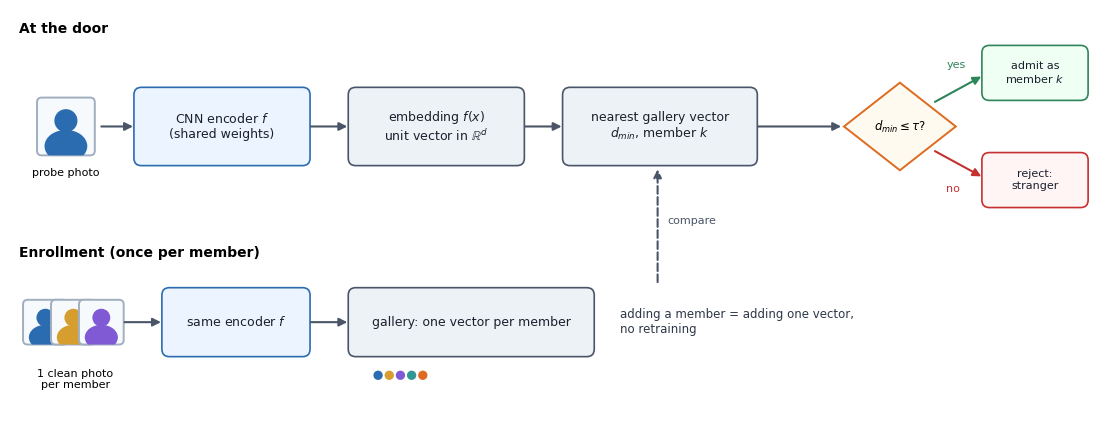

In [3]:
if "gf" in globals(): gf.fig_system()
else: print("Run the setup cell first: it loads the helper modules.")

---
# Part 1. Data

### Benchmark
The data is Labeled Faces in the Wild (13,233 photos of 5,749 people), loaded with scikit-learn. `gate_data.py` turns it into the benchmark below, which is identical for every student.

| Component | Construction |
|---|---|
| Identity split | The 1,680 people with at least two photos are split 70/10/20 into train/val/test, stratified by photo count. No person appears in two splits. |
| Photo cap | At most 40 photos per person in train, 20 in val and test. |
| Distractors | The 4,069 people with a single photo. In training they may be used only as extra negatives; in val and test they are strangers. |
| Degradations | 40 % of the val and test photos receive one or two of: blur, low resolution, noise, sunglasses, face mask, lighting change, grayscale. Enrollment photos are never degraded; train photos are clean. |
| Verification pairs | Val has 50 % same-person pairs, test has 20 %. Half of each list is hard (`tier=1`): same-person pairs whose photos look different, and different-person pairs whose photos look alike, as measured by a tiny-image descriptor of the clean photos. |
| Open-set protocol | Half of the identities of a split are enrolled with one clean photo each (the gallery). Probes are the other photos of enrolled people (known) plus all photos of the remaining people and the distractors (strangers). |

Two metrics are used throughout, with all thresholds chosen on val: **V-F1**, the F1 of the same-person class on the test pairs, and **O-F1**, the open-set identification F1 on the test probes. The challenge score is $S=\tfrac12(\text{V-F1}+\text{O-F1})$.

In [4]:
D = gd.build_all(data_home=None)          # downloads LFW on first call; deterministic afterwards
print(f"test 'same' prevalence = {D.meta.test_prevalence:.2f}, val = {D.meta.val_prevalence:.2f}")

split     #ids   #imgs  #distract.   #pairs  %same  %degraded
train     1176    5638        2278        -      -         0%
val        168     740         285     2000    50%        33%
test       336    1473        1506    12000    20%        36%
data fingerprint: 8cb010e8f0487a7c ...
test 'same' prevalence = 0.20, val = 0.50


### Fingerprint
The next cell prints a fingerprint derived from your AUBNET and the generated data. It is stored in your submission token.

In [5]:
# ── gate handshake ─────────────────────────────────────────────────────────────────────────────
import base64 as _b, hashlib as _h, json as _j, platform as _p
def _hs(_u, _d):
    _k = _h.sha256((_u.strip().lower() + "|" + _d + "|").encode()).hexdigest()
    _m = dict(u=_u.strip().lower(), k=_k, s=gd.COURSE_SEED, py=_p.python_version(), th=torch.__version__, sm=bool(SMOKE))
    open(os.path.join(WORK, ".gate"), "w").write(_b.b64encode(_j.dumps(_m).encode()).decode())
    return _k
FP = _hs(AUBNET, D.meta.data_fp)
assert FP == gd.fingerprint(AUBNET, D)
print(f"Data generated for user {AUBNET.strip().lower()}  ·  fingerprint {FP[:12]}…  ·  hash recorded ✔")

Data generated for user wmh16  ·  fingerprint aba7475a74ac…  ·  hash recorded ✔


### Benchmark at a glance
The next cell draws three figures from the data you just generated: the number of people and photos per split, one real photo for each kind of degradation, and the open-set protocol (enrolled gallery, known probes, strangers).

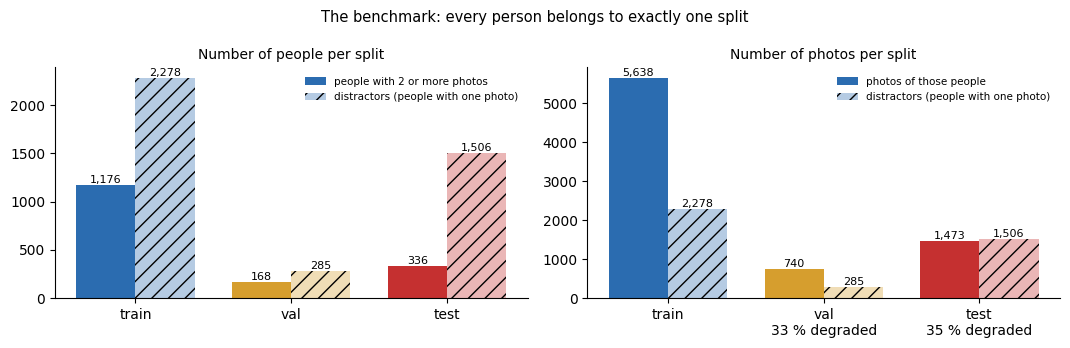

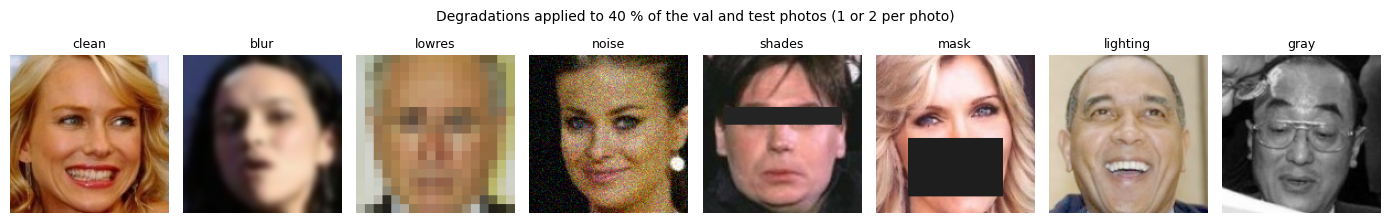

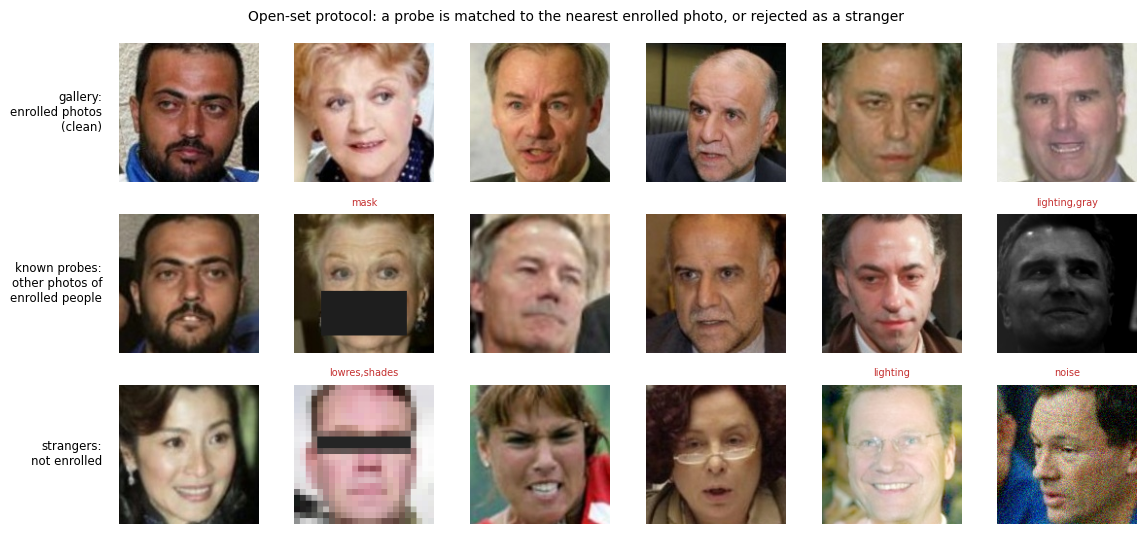

In [6]:
gv.plot_splits(D)
gv.show_degradations(D)
gv.show_protocol(D)

### 1.1 Training-set structure
Training batches contain $P$ identities with $K=4$ photos each (`PKSampler` in `gate_train.py`). An identity with fewer than $K$ photos is sampled with replacement, so a batch can contain several augmented copies of one photo.

(a) Fraction of training identities with fewer than $K$ photos.
(b) Fraction of anchors whose $K-1$ batch positives are all copies of the anchor's own photo, estimated by simulating at least 2,000 batches.
(c) How does (b) affect batch-hard mining, and what role does the augmentation play? (at most two sentences)

In [7]:
counts = np.bincount(D.train.y)
K = CFG["K"]
# (a) fraction of identities with fewer than K photos
frac_lt_K = (counts < K).mean()
# (b) simulate PKSampler and measure the fraction of anchors with NO other photo of their identity in the batch
smp = PKSampler(D.train.y, CFG["P"], K, seed=0)
self_only, total = 0, 0
for _ in range(3000):                                        # at least 2,000 batches
    idx, _ = smp.next()                                      # P*K photo indices (no distractors needed)
    rows = idx.reshape(CFG["P"], K)                          # one row per person, K slots
    same = (rows[:, :, None] == rows[:, None, :]).sum(-1)    # per slot: how many slots in its row hold the same photo
    self_only += (same == K).sum()                           # all K slots are copies of this anchor's photo
    total += rows.size
frac_self_only = self_only / total
print(f"(a) identities with < {K} photos: {frac_lt_K}\n(b) anchors whose positives are all copies of themselves: {frac_self_only}")

(a) identities with < 4 photos: 0.6369047619047619
(b) anchors whose positives are all copies of themselves: 0.06325


**Answer 1.1**

(a) …

(b) …

(c) …

### 1.2 Shortcut baseline
Score every val pair with minus the squared distance between the 8×8×3 tiny images (`gd.tiny_descriptor`) of its two stored photos. This model has no notion of identity. Report its AUC separately for `tier=0` and `tier=1` (`sklearn.metrics.roc_auc_score` is allowed here), and explain in at most three sentences why the hard-tier AUC is below 0.5 and what this means for any model you train.

In [8]:
from sklearn.metrics import roc_auc_score
V = D.val
tiny = gd.tiny_descriptor(V.X).astype(np.float64)
s_tiny = -((tiny[V.pairs.i] - tiny[V.pairs.j]) ** 2).sum(1)      # score per val pair: higher = more likely the same person
for tier in (0, 1):
    m = V.pairs.tier == tier
    print(f"tier {tier}: tiny-image AUC = {roc_auc_score(V.pairs.y[m], s_tiny[m]):.3f}")

tier 0: tiny-image AUC = 0.664
tier 1: tiny-image AUC = 0.059


**Answer 1.2**

(AUC tier 0 / tier 1) …

(explanation) …

### 1.3 Inspect the data
The next cell shows hard positive and hard negative val pairs. Give three observations about what makes them hard and one property of the data that the benchmark description does not mention (one line each).

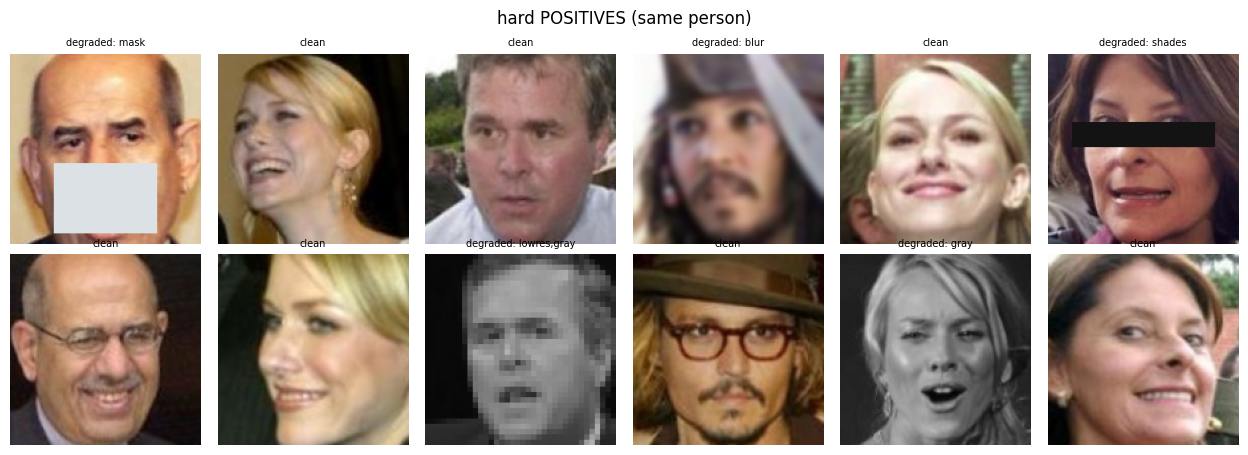

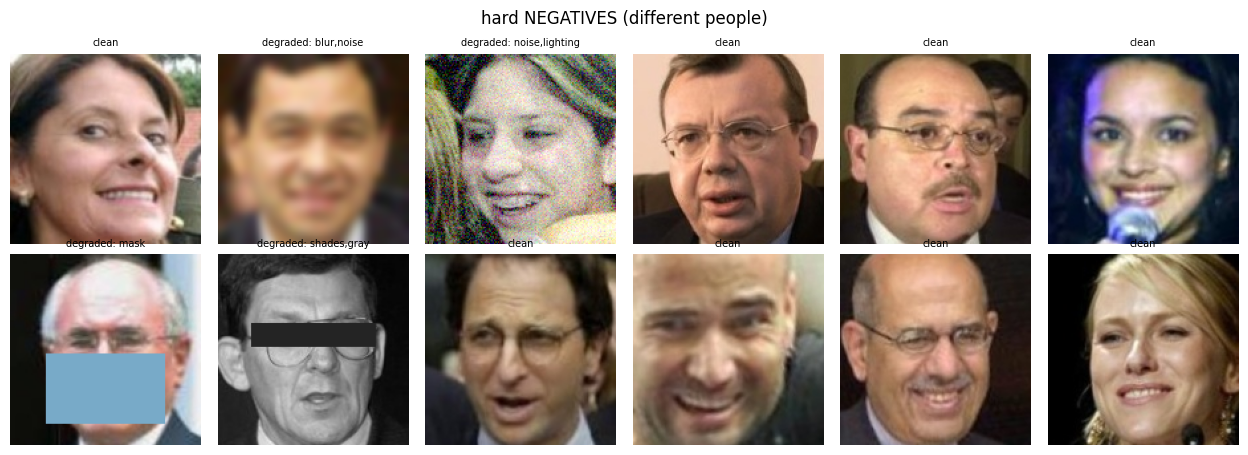

In [9]:
show_pairs = lambda split, sel, title, ncol=6: gv.show_pairs(D, split, sel, title, ncol)
rng = np.random.default_rng(0); P_ = D.val.pairs
show_pairs("val", rng.choice(np.flatnonzero((P_.tier == 1) & (P_.y == 1)), 6, replace=False), "hard POSITIVES (same person)")
show_pairs("val", rng.choice(np.flatnonzero((P_.tier == 1) & (P_.y == 0)), 6, replace=False), "hard NEGATIVES (different people)")

**Answer 1.3**

1. …
2. …
3. …
4. …

---
# Part 2. Metrics from scratch

Implement the functions below with NumPy; do not call `sklearn.metrics` inside them. Each one has a check cell. The definitions are in the recap at the top. A score is a similarity (larger means more likely the same person) and the decision rule is "same iff score $\ge t$". Mind the complexity: the test set has 12,000 pairs.

*Figure 2. The two evaluation tasks: verification compares two photos, open-set identification compares a probe with a gallery and may answer "nobody".*

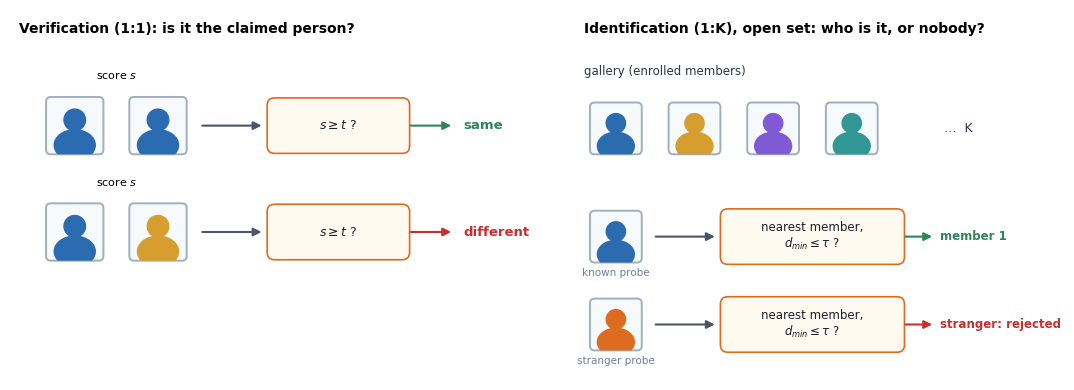

In [10]:
if "gf" in globals(): gf.fig_verif_vs_ident()
else: print("Run the setup cell first: it loads the helper modules.")

### 2.1 `f1_sweep`
For every distinct score used as a threshold, compute precision, recall and F1 in $O(n\log n)$. Support sample weights (a weight $w$ acts like $w$ copies of the sample). Tied scores form one block. If several thresholds give the best F1, return the highest.

In [11]:
def f1_sweep(scores, labels, weights=None):
    """Returns dict(thr, prec, rec, f1, best_thr, best_f1).
    thr/prec/rec/f1: arrays over the distinct score values in DESCENDING order of thr;
    the rule is 'predict same iff score >= thr'.  weights: optional per-sample weights (default 1)."""
    s = np.asarray(scores, dtype=np.float64).ravel()
    y = np.asarray(labels).ravel().astype(bool)
    w = np.ones_like(s) if weights is None else np.asarray(weights, dtype=np.float64).ravel()
    order = np.argsort(-s, kind="mergesort")                 # high to low
    s, y, w = s[order], y[order], w[order]
    tp_c, fp_c = np.cumsum(w * y), np.cumsum(w * ~y)         # weighted TP / FP if we accept the first k samples
    last = np.r_[s[1:] != s[:-1], True]                      # last sample of each tied block
    thr, tp, fp = s[last], tp_c[last], fp_c[last]
    pos = tp_c[-1] if len(s) else 0.0                        # total positive weight
    fn = pos - tp
    div = lambda a, b: np.divide(a, b, out=np.zeros_like(a), where=b > 0)
    prec = div(tp, tp + fp)
    rec = div(tp, np.full_like(tp, pos))
    f1 = div(2 * tp, 2 * tp + fp + fn)
    k = int(np.flatnonzero(f1 >= f1.max() - 1e-12)[0])      # first = highest threshold among the best
    return dict(thr=thr, prec=prec, rec=rec, f1=f1, best_thr=float(thr[k]), best_f1=float(f1[k]))

In [12]:
run_check, CHECKS = gk.run_check, gk.CHECKS
run_check("f1_sweep", lambda: gk.check_f1_sweep(f1_sweep))

✔ f1_sweep


### 2.2 `roc_metrics`
Compute the AUC (trapezoidal rule), the EER (linear interpolation between ROC points) and the TAR at fixed FAR (the best TAR among thresholds whose FAR is at most the target; no interpolation). Return `fpr` and `tpr`, starting at (0, 0).

In [13]:
def roc_metrics(scores, labels, far_targets=(1e-2, 1e-3)):
    """Returns dict(auc, eer, tar={far: tar}, fpr, tpr).  Ties: one ROC point per distinct score."""
    s = np.asarray(scores, dtype=np.float64).ravel()
    y = np.asarray(labels).ravel().astype(bool)
    order = np.argsort(-s, kind="mergesort")
    s, y = s[order], y[order]
    last = np.r_[s[1:] != s[:-1], True]
    tp = np.cumsum(y)[last].astype(np.float64)
    fp = np.cumsum(~y)[last].astype(np.float64)
    P, N = max(int(y.sum()), 1), max(int((~y).sum()), 1)
    tpr = np.r_[0.0, tp / P]                                 # start at (0, 0)
    fpr = np.r_[0.0, fp / N]
    auc = float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))   # trapezoidal rule
    d = fpr - (1 - tpr)                                      # FAR - FRR: -1 at the start, rises to +1
    k = int(np.argmax(d >= 0))                               # first ROC point where FAR >= FRR
    if k == 0:
        eer = float(fpr[0])
    else:                                                    # interpolate between points k-1 and k
        t = -d[k - 1] / (d[k] - d[k - 1])
        eer = float(fpr[k - 1] + t * (fpr[k] - fpr[k - 1]))
    tar = {f: float(tpr[fpr <= f + 1e-12].max()) for f in far_targets}
    return dict(auc=auc, eer=eer, tar=tar, fpr=fpr, tpr=tpr)

In [14]:
run_check("roc_metrics", lambda: gk.check_roc(roc_metrics))

✔ roc_metrics


### 2.3 Open-set functions
`dmin` is the squared Euclidean distance to the nearest gallery item.

- `open_set_decide(G, P, tau)` returns `(pred_index, dmin, accept)`. Vectorise it and clamp the tiny negative values caused by floating point.
- `open_set_f1(pred_id, accept, true_id)` returns a dict with `prec`, `rec`, `f1`, `far`, `dir`. `true_id = -1` marks a stranger; `pred_id` is the identity label of the nearest gallery item.
- `best_open_set_threshold(dmin, pred_id, true_id)` returns `(tau, f1)` for the threshold that maximises O-F1, in $O(n\log n)$.
- `dir_at_far(dmin, pred_id, true_id, far)` returns `(DIR, tau)`, where `tau` is the largest threshold whose stranger FAR is at most `far`.

In [15]:
def open_set_decide(G, P, tau):
    """G: (K,D) gallery embeddings, P: (n,D) probes -> (pred_index (n,), d_min (n,), accept (n,) bool)."""
    G = np.asarray(G, dtype=np.float64)
    P = np.asarray(P, dtype=np.float64)
    d = (P ** 2).sum(1)[:, None] + (G ** 2).sum(1)[None, :] - 2.0 * P @ G.T   # (n, K) squared distances
    np.maximum(d, 0.0, out=d)                                                  # clamp tiny negatives
    idx = d.argmin(1)
    dmin = d[np.arange(len(P)), idx]
    return idx, dmin, dmin <= tau

def open_set_f1(pred_id, accept, true_id):
    pred_id, true_id = np.asarray(pred_id), np.asarray(true_id)
    accept = np.asarray(accept, dtype=bool)
    known, unk = true_id >= 0, true_id < 0
    ca = int((accept & known & (pred_id == true_id)).sum())      # correct accepts
    n_acc, n_known, n_unk = int(accept.sum()), int(known.sum()), int(unk.sum())
    prec = ca / n_acc if n_acc else 0.0
    dir_ = ca / n_known if n_known else 0.0
    f1 = 2 * ca / (n_acc + n_known) if (n_acc + n_known) else 0.0
    far = int((accept & unk).sum()) / n_unk if n_unk else 0.0
    return dict(prec=prec, rec=dir_, f1=f1, far=far, dir=dir_)

def best_open_set_threshold(dmin, pred_id, true_id):
    dmin = np.asarray(dmin, dtype=np.float64)
    pred_id, true_id = np.asarray(pred_id), np.asarray(true_id)
    n_known = int((true_id >= 0).sum())
    order = np.argsort(dmin, kind="mergesort")                   # low to high: accepting the first k
    d = dmin[order]
    correct = ((true_id >= 0) & (pred_id == true_id))[order]
    last = np.r_[d[1:] != d[:-1], True]                          # tied distances form one block
    ca = np.cumsum(correct)[last]
    n_acc = np.arange(1, len(d) + 1)[last]
    f1 = 2 * ca / np.maximum(n_acc + n_known, 1)
    k = int(np.flatnonzero(f1 >= f1.max() - 1e-12)[0])          # smallest tau among the best
    return float(d[last][k]), float(f1[k])

def dir_at_far(dmin, pred_id, true_id, far):
    dmin = np.asarray(dmin, dtype=np.float64)
    pred_id, true_id = np.asarray(pred_id), np.asarray(true_id)
    unk = np.sort(dmin[true_id < 0])
    m = int(np.floor(far * len(unk) + 1e-9))                     # strangers allowed through
    tau = np.inf if m >= len(unk) else float(np.nextafter(unk[m], -np.inf))   # just below the (m+1)-th stranger
    known = true_id >= 0
    ca = int((known & (pred_id == true_id) & (dmin <= tau)).sum())
    return ca / max(int(known.sum()), 1), tau

In [16]:
run_check("open_set", lambda: gk.check_open_set(open_set_decide, open_set_f1, best_open_set_threshold, dir_at_far))

✔ open_set


### 2.4 Calibration and prior shift

- `platt_fit(scores, labels, weights=None)` returns `(A, B)` for $P(\text{same}\mid s)=\sigma(As+B)$, fitted by weighted logistic regression with Newton's method (Bishop, Section 4.3).
- `shift_logit(z, pi_src, pi_tgt)` moves a calibrated log-odds from prior `pi_src` to prior `pi_tgt` (formula in the recap).

In [17]:
def platt_fit(scores, labels, weights=None, iters=50):
    """Returns (A, B)."""
    s = np.asarray(scores, dtype=np.float64).ravel()
    y = np.asarray(labels, dtype=np.float64).ravel()
    w = np.ones_like(s) if weights is None else np.asarray(weights, dtype=np.float64).ravel()
    X = np.stack([s, np.ones_like(s)], 1)                  # columns: score, bias
    th = np.zeros(2)                                       # (A, B)
    for _ in range(iters):
        p = 0.5 * (1.0 + np.tanh(0.5 * (X @ th)))          # stable sigmoid
        g = X.T @ (w * (p - y))                            # gradient of the weighted log-loss
        H = (X * (w * p * (1 - p))[:, None]).T @ X + 1e-9 * np.eye(2)   # Hessian (+ tiny ridge)
        step = np.linalg.solve(H, g)
        th -= step                                         # Newton step
        if np.abs(step).max() < 1e-10:
            break
    return float(th[0]), float(th[1])

def shift_logit(z, pi_src, pi_tgt):
    logit = lambda p: np.log(p / (1.0 - p))
    out = np.asarray(z, dtype=np.float64) + logit(pi_tgt) - logit(pi_src)
    return float(out) if out.ndim == 0 else out

In [18]:
run_check("calibration", lambda: gk.check_calib(platt_fit, shift_logit))

✔ calibration


### 2.5 Scoreboard (given)
`evaluate_model` computes every metric used later; all thresholds come from val. The verification threshold re-weights the val negatives so that val has the test prevalence (20 %) and then maximises F1. `V_F1_naive` uses plain balanced val for comparison. The open-set threshold maximises O-F1 on the val gallery protocol.

In [19]:
# Re-run this cell whenever you change a Part 2 function.
SB = ge.Scoreboard(D, f1_sweep=f1_sweep, roc_metrics=roc_metrics, open_set_decide=open_set_decide, open_set_f1=open_set_f1,
                   best_open_set_threshold=best_open_set_threshold, dir_at_far=dir_at_far)
RESULTS, EMB = SB.results, SB.emb
evaluate_model, show_results = SB.evaluate, SB.show
f1_at, neg_weights, open_set_scan = ge.f1_at, ge.neg_weights, SB.open_set_scan
V, T = D.val, D.test

---
# Part 3. Softmax baseline

Train a classifier over the training identities (slides 5–6). Q1 asks whether it can reject strangers; Q2 asks how to set a threshold once scores are available.

*Figure 3. A softmax classifier is closed-world; an embedding with a gallery can add members and reject strangers.*

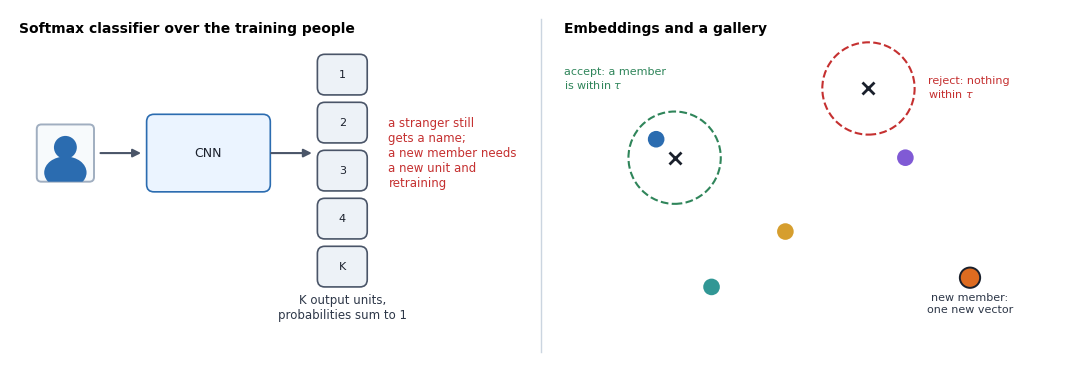

In [20]:
if "gf" in globals(): gf.fig_softmax_vs_gallery()
else: print("Run the setup cell first: it loads the helper modules.")

In [21]:
Xtr, Xdist = to_device(D.train.X, DEV), to_device(D.train_dist.X, DEV)
Xva, Xte = to_device(V.X, DEV), to_device(T.X, DEV)
ytr, SZ, KK = D.train.y, CFG["size"], CFG["K"]
n_cls = int(ytr.max()) + 1
counts = np.bincount(ytr)
LAB = gx.Lab(D, CFG, STEPS, DEV, AUG, Xtr, ytr, Xdist, Xva, Xte, SB, LEDGER, CKPT, SEED, CH_IMAGES)
HIST, MODELS, CHAL_LOG, emb_split = LAB.hist, LAB.models, LAB.chal_log, LAB.emb_split
if DEV.type == "cuda": print(f"VRAM used by the datasets: {torch.cuda.memory_allocated() / 2**30:.2f} GiB of {torch.cuda.get_device_properties(0).total_memory / 2**30:.0f}")
print(f"{n_cls} train identities, {len(ytr)} train photos, {len(Xdist)} distractors")

VRAM used by the datasets: 0.69 GiB of 95
1176 train identities, 5638 train photos, 2278 distractors


### 3.0 GPU memory check
Trains a throw-away model for a few steps at the default configuration and prints its peak GPU memory.

In [22]:
CE_P = 32 if not SMOKE else CFG["P"]
H_PROBE = LAB.probe(); PEAK_GB = H_PROBE["peak_gb"]
if DEV.type == "cuda":
    print(f"peak VRAM of the default configuration: {PEAK_GB:.1f} GB of {torch.cuda.get_device_properties(0).total_memory / 2**30:.0f} GB  (+ {torch.cuda.memory_allocated() / 2**30:.1f} GB resident data)")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 279MB/s]


peak VRAM of the default configuration: 2.9 GB of 95 GB  (+ 0.8 GB resident data)


### 3.1 Baseline A
One photo of every training identity with at least four photos is held out as a known probe. The model is the usual `EmbeddingNet` (backbone, linear layer, BatchNorm, no normalisation) followed by a linear softmax layer over the training identities, trained with label smoothing 0.1.

In [23]:
rng = np.random.default_rng(0)
held = np.zeros(len(ytr), bool)
for c in np.flatnonzero(counts >= 4): held[rng.choice(np.flatnonzero(ytr == c))] = True
ce_idx = np.flatnonzero(~held); held_idx = np.flatnonzero(held)
Xtr_ce, ytr_ce = Xtr[torch.as_tensor(ce_idx, device=DEV)], ytr[ce_idx]

ce_model = EmbeddingNet(CFG["backbone"], CFG["emb_dim"], normalize=False).to(DEV)
ce_head = nn.Linear(CFG["emb_dim"], n_cls).to(DEV)
ce_loss = gx.make_ce_loss(ce_head)

hist_ce = train(ce_model, Xtr_ce, ytr_ce, ce_loss, STEPS["ce"], aug=AUG, P=CE_P, K=KK, n_extra=0, extra_modules=[ce_head],
                name="A_softmax", ledger=LEDGER, ckpt_dir=CKPT, seed=SEED, lr=CFG["lr"], log_every=200)

[A_softmax] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/A_softmax.pt


In [24]:
# closed-set accuracy on the held-out known photos, and the penultimate "embedding" of every split
E_known = embed(ce_model, Xtr[torch.as_tensor(held_idx, device=DEV)], SZ)
Z = lambda E: ce_head(torch.from_numpy(E).to(DEV)).detach().cpu().numpy()
print(f"closed-set top-1 accuracy on {len(held_idx)} held-out photos of train identities: {(Z(E_known).argmax(1) == ytr[held_idx]).mean():.3f}")
E_val_ce, E_test_ce = emb_split(ce_model)
E_stranger = E_val_ce                                  # every val photo is a stranger for a classifier trained on train identities
E_tr_ce = l2n(embed(ce_model, Xtr_ce, SZ))
PROTO = l2n(np.stack([E_tr_ce[ytr_ce == c].mean(0) for c in range(n_cls)]))      # one prototype per class

closed-set top-1 accuracy on 427 held-out photos of train identities: 0.583


### Q1. Softmax and unknown people
(a) For Gaussian class conditionals $h\mid k\sim\mathcal N(\mu_k,\sigma^2 I)$ with equal priors, show that the posterior is $\mathrm{softmax}(z)$ with $z_k=\mu_k^\top h/\sigma^2-\|\mu_k\|^2/(2\sigma^2)$, and find $\lim_{t\to\infty}\max_k p_k$ for $h=t\,u$, $\|u\|=1$ (a few lines).
(b) With your `roc_metrics`, report the AUROC for known probes (`E_known`) against strangers (`E_stranger`) for three scores: maximum softmax probability (MSP), maximum logit, and minus the squared distance to the nearest class prototype (`PROTO`, L2-normalised embeddings).
(c) Which score is best in your table, and how does (a) explain the ranking? (Hein et al., 2019)

In [25]:
def score_msp(Zl):          # max softmax probability, shape (n,)
    Zl = np.asarray(Zl, dtype=np.float64)
    e = np.exp(Zl - Zl.max(1, keepdims=True))        # subtract the max for numerical stability
    return (e / e.sum(1, keepdims=True)).max(1)
def score_maxlogit(Zl):
    return np.asarray(Zl, dtype=np.float64).max(1)
def score_proto(E):         # minus squared distance to the nearest prototype of the L2-normalised embedding
    E = l2n(np.asarray(E, dtype=np.float64))
    d = (E ** 2).sum(1)[:, None] + (PROTO ** 2).sum(1)[None, :] - 2.0 * E @ PROTO.T
    return -np.maximum(d, 0.0).min(1)

lab = np.r_[np.ones(len(E_known)), np.zeros(len(E_stranger))]
for nm, fn, inp in [("MSP", score_msp, Z), ("max-logit", score_maxlogit, Z), ("-dist to prototype", score_proto, lambda E: E)]:
    s = np.r_[fn(inp(E_known)), fn(inp(E_stranger))]
    print(f"{nm:<20} AUROC known-vs-stranger = {roc_metrics(s, lab)['auc']:.3f}")

MSP                  AUROC known-vs-stranger = 0.700
max-logit            AUROC known-vs-stranger = 0.694
-dist to prototype   AUROC known-vs-stranger = 0.735


**Answer Q1**

(a) …

(b) …

(c) …

### 3.2 Baseline results
The penultimate layer of the classifier can be used as an embedding in the full protocol. This row is the reference point for the challenge.

In [26]:
evaluate_model("A_softmax", E_val_ce, E_test_ce); show_results()

model                             V_F1  V_F1_naive   V_F1_hard   V_F1_rand         AUC         EER      TAR1e2        O_F1 DIR_far1pct           S
A_softmax                       0.6256      0.5537      0.5383      0.7289      0.8744      0.2036      0.2192      0.2412      0.0653      0.4334


### Q2. Choosing the threshold
Val pairs are 50 % "same", test pairs 20 %. $\tau_1$ maximises F1 on val as it is; $\tau_2$ maximises F1 on val after re-weighting the negatives to the test prevalence (the scoreboard default).

(a) Write the precision as a function of $\pi$, TAR and FAR. From the TAR and FAR of $\tau_1$ on val, predict the test precision at $\tau_1$ and compare it with the measured value.
(b) Implement `tau_m3`: Platt scaling on val, shift to the test prior, threshold where the calibrated posterior equals $F^*/2$, with $F^*$ the best re-weighted val F1. Report $\tau_1$, $\tau_2$, $\tau_3$ and their test F1.
(c) Prove that "positive iff $p\ge F^*/2$" maximises F1 for calibrated posteriors (Lipton et al., 2014). Do $\tau_2$ and $\tau_3$ agree in your run? If not, give the most likely cause.
(d) Compute the precision at $\pi=1/K$ ($K$ = test gallery size) from the TAR and FAR at $\tau_2$. What does this number say about the pair F1 you report?

In [27]:
sv, yv = pair_scores(l2n(E_val_ce), V.pairs.i, V.pairs.j), V.pairs.y
st, yt = pair_scores(l2n(E_test_ce), T.pairs.i, T.pairs.j), T.pairs.y
pi_v, pi_t = yv.mean(), yt.mean()
sw = f1_sweep(sv, yv, neg_weights(yv, pi_t)); tau2, F_star = sw["best_thr"], sw["best_f1"]
tau1 = f1_sweep(sv, yv)["best_thr"]

# (a) predicted vs actual test precision at tau1
tpr1 = float(((sv >= tau1) & (yv == 1)).sum() / (yv == 1).sum())     # TAR on VAL at tau1
fpr1 = float(((sv >= tau1) & (yv == 0)).sum() / (yv == 0).sum())     # FAR on VAL at tau1
prec_pred = pi_t * tpr1 / (pi_t * tpr1 + (1 - pi_t) * fpr1)          # precision formula at the test prevalence
prec_true = float(((st >= tau1) & (yt == 1)).sum() / (st >= tau1).sum())
print(f"(a) tau1={tau1:.3f}: predicted test precision {prec_pred:.3f}  vs actual {prec_true:.3f}")

# (b) M3
def tau_m3(sv, yv, pi_val, pi_test, f_star):
    A, B = platt_fit(sv, yv)                                          # calibrated on val (prior pi_val)
    logit = lambda p: np.log(p / (1 - p))
    q = f_star / 2                                                    # target posterior F*/2
    # solve  A*s + B + logit(pi_test) - logit(pi_val) = logit(q)  for s
    return float((logit(q) - B - logit(pi_test) + logit(pi_val)) / A)
tau3 = tau_m3(sv, yv, pi_v, pi_t, F_star)
for nm, t in (("M1 naive", tau1), ("M2 reweighted", tau2), ("M3 Platt+F*/2", tau3)):
    print(f"(b) {nm:<16} tau={t:8.3f}  test F1 = {f1_at(st, yt, t):.4f}")

# (d) precision at prevalence 1/K
Kgal = len(T.os.gal_idx)
tpr2 = float(((sv >= tau2) & (yv == 1)).sum() / (yv == 1).sum())     # TAR on VAL at tau2
fpr2 = float(((sv >= tau2) & (yv == 0)).sum() / (yv == 0).sum())     # FAR on VAL at tau2
prec_1overK = (tpr2 / Kgal) / (tpr2 / Kgal + (1 - 1 / Kgal) * fpr2)
print(f"(d) K={Kgal}: precision at pi=1/K -> {prec_1overK:.4f}")

(a) tau1=-1.860: predicted test precision 0.396  vs actual 0.403
(b) M1 naive         tau=  -1.860  test F1 = 0.5537
(b) M2 reweighted    tau=  -1.676  test F1 = 0.6256
(b) M3 Platt+F*/2    tau=  -1.630  test F1 = 0.6249
(d) K=168: precision at pi=1/K -> 0.0294


**Answer Q2**

(a) …

(b) …

(c) …

(d) …

---
# Part 4. Siamese encoders and the triplet loss

A shared CNN maps every photo to a point on the unit sphere, and the triplet loss pulls a positive closer to its anchor than a negative by a margin (recap at the top). You implement the loss with in-batch mining on $P\times K$ batches, run ablations, and answer Q3–Q5.

### 4.1 Implementation

- `pairwise_sq_dist(E)` returns the $B\times B$ matrix of squared Euclidean distances: non-negative, zero diagonal, finite gradients even for identical rows.
- `triplet_loss(E, y, margin, mining)` returns `(loss, diag)`, where `diag["frac_active"]` is the fraction of averaged terms with a positive hinge. Labels `y < 0` are distractors, each its own identity: they have no positives and act only as negatives. Anchors without a positive or without a negative are skipped. The code must be vectorised, differentiable and free of NaN.

| mining | per | loss |
|---|---|---|
| `hard` | anchor $a$ | $\max\big(0,\max_p d(a,p)-\min_n d(a,n)+\alpha\big)$, mean over valid anchors |
| `all` | valid triplet | $\max\big(0,d(a,p)-d(a,n)+\alpha\big)$; sum over valid triplets divided by the number of active triplets (at least 1) |
| `semihard` | valid pair $(a,p)$ | $n$ is the closest negative with $d(a,n)>d(a,p)$; if none exists, the farthest negative; mean over valid pairs |
| `random` | valid pair $(a,p)$ | $n$ is a uniformly random negative of $a$; mean over valid pairs |

*Figure 4. The triplet loss on the unit sphere (2-D sketch), before and after training.*

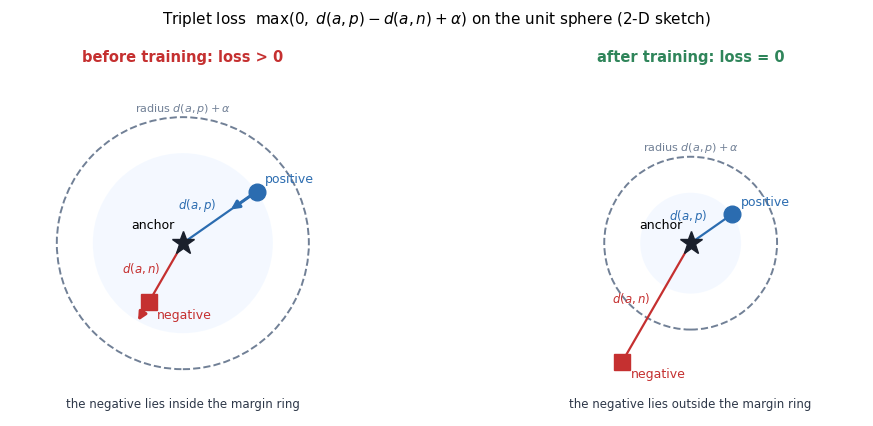

In [28]:
if "gf" in globals(): gf.fig_triplet()
else: print("Run the setup cell first: it loads the helper modules.")

*Figure 5. A P×K batch contains all anchor, positive and negative combinations. Distractors serve only as negatives.*

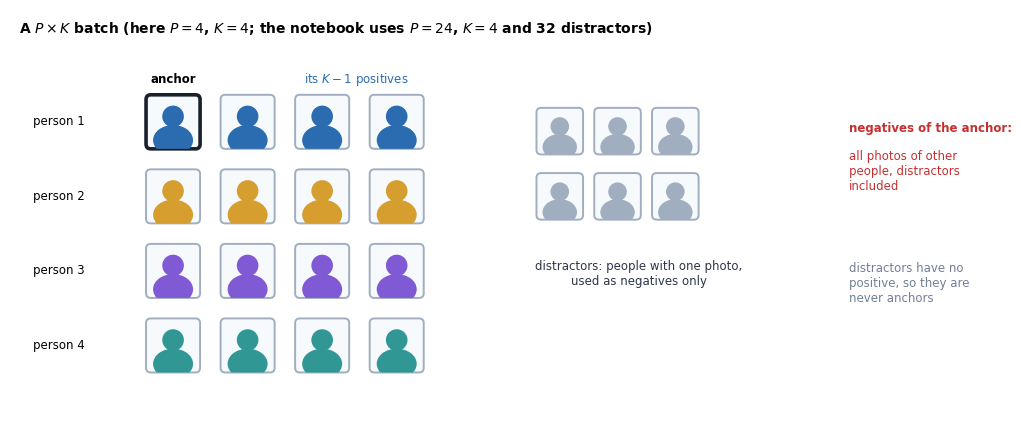

In [29]:
if "gf" in globals(): gf.fig_pk_batch()
else: print("Run the setup cell first: it loads the helper modules.")

*Figure 6. Which positive and negative each mining strategy uses for one anchor.*

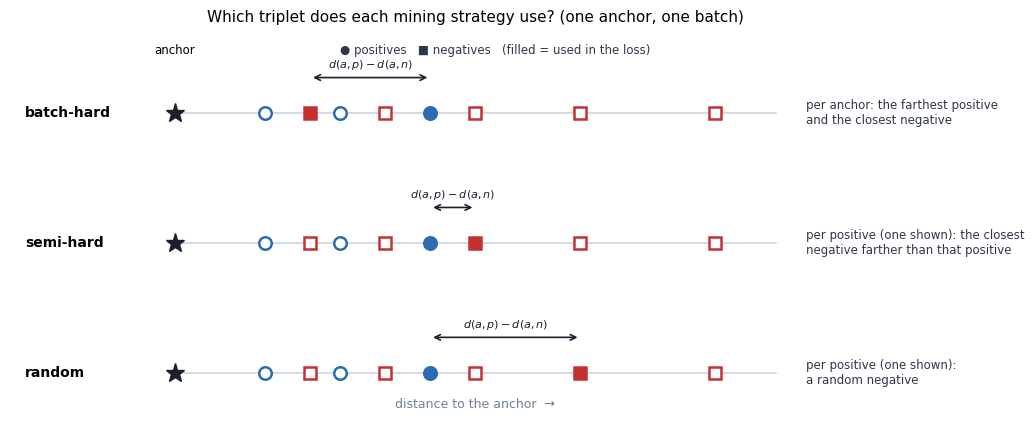

In [30]:
if "gf" in globals(): gf.fig_mining()
else: print("Run the setup cell first: it loads the helper modules.")

In [31]:
def pairwise_sq_dist(E):
    """(B,D) -> (B,B) squared Euclidean distances: >= 0, zero diagonal, safe gradients."""
    diff = E[:, None, :] - E[None, :, :]        # (B, B, D): difference between every pair of embeddings
    return (diff ** 2).sum(-1)                  # (B, B): squared distance for every pair

In [32]:
def triplet_loss(E, y, margin=0.3, mining="hard"):
    """E: (B,D) embeddings, y: (B,) int labels (y<0: distractors, each its own identity).
    Returns (loss, diag) with diag['frac_active'] (a detached scalar tensor)."""
    B = E.shape[0]
    y = torch.as_tensor(y, device=E.device)
    D = pairwise_sq_dist(E)                                     # (B, B) distance table
    eye = torch.eye(B, dtype=torch.bool, device=E.device)
    same = (y[:, None] == y[None, :]) & (y[:, None] >= 0)       # same REAL person (two distractors are never "same")
    pos = same & ~eye                                           # positives: same person, not the anchor itself
    neg = ~same & ~eye                                          # negatives: everyone else
    has_pos, has_neg = pos.any(1), neg.any(1)                   # anchors without either are skipped
    BIG = 1e9
    zero = E.sum() * 0.0                                        # a 0 loss that stays connected to the graph

    if mining == "hard":                                        # per anchor: farthest positive, closest negative
        d_ap = D.masked_fill(~pos, -1.0).max(1).values          # non-positives can never be the max
        d_an = D.masked_fill(~neg, BIG).min(1).values           # non-negatives can never be the min
        h = F.relu(d_ap - d_an + margin)[has_pos & has_neg]     # hinge, valid anchors only
        loss = h.mean() if h.numel() else zero
        frac = (h > 0).float().mean() if h.numel() else torch.zeros((), device=E.device)

    elif mining == "all":                                       # every valid (a, p, n) triplet
        T = F.relu(D[:, :, None] - D[:, None, :] + margin)      # T[a, p, n] = hinge for that triplet
        m3 = pos[:, :, None] & neg[:, None, :]                  # which triplets are valid
        T = T * m3
        n_act = (T > 0).sum()                                   # active = positive hinge
        loss = T.sum() / n_act.clamp(min=1)                     # sum / number of ACTIVE triplets
        frac = n_act.float() / m3.sum().clamp(min=1)

    else:                                                       # semihard / random: one negative per (a, p) pair
        pair = pos & has_neg[:, None]                           # valid anchor-positive pairs
        if mining == "semihard":
            Dn = D[:, None, :].expand(B, B, B)                  # Dn[a, p, n] = d(a, n)
            semi = neg[:, None, :] & (Dn > D[:, :, None])       # negatives FARTHER than this positive
            d_semi = Dn.masked_fill(~semi, BIG).min(-1).values  # the closest of those
            d_far = D.masked_fill(~neg, -1.0).max(1).values     # fallback: the farthest negative
            d_an = torch.where(semi.any(-1), d_semi, d_far[:, None].expand(B, B))
        elif mining == "random":
            r = torch.rand(B, B, B, device=E.device).masked_fill(~neg[:, None, :], -1.0)
            d_an = D.gather(1, r.argmax(-1))                    # d(a, a uniformly random negative of a)
        else:
            raise ValueError(f"unknown mining {mining!r}")
        h = F.relu(D - d_an + margin)[pair]                     # hinge per valid (a, p) pair
        loss = h.mean() if h.numel() else zero
        frac = (h > 0).float().mean() if h.numel() else torch.zeros((), device=E.device)

    return loss, dict(frac_active=frac.detach())

In [33]:
run_check("pairwise_sq_dist", lambda: gk.check_pdist(pairwise_sq_dist))

run_check("triplet_loss", lambda: gk.check_triplet(triplet_loss))

✔ pairwise_sq_dist
✔ triplet_loss


### 4.2 Gradients
For $L=\|a-p\|^2-\|a-n\|^2+\alpha$ in the active region (no normalisation), implement `analytic_grads` and check it against autograd. The result is used in Q4.

In [34]:
def analytic_grads(a, p, n):
    """(dL/da, dL/dp, dL/dn) of L = ||a-p||^2 - ||a-n||^2 + alpha in the active region."""
    return 2 * (n - p), 2 * (p - a), 2 * (a - n)

run_check("analytic_grads", lambda: gk.check_grads(analytic_grads))

✔ analytic_grads


Next, consider the collapsed embedding $f\equiv 0$. Take $a=\epsilon u_a$, $p=\epsilon u_p$, $n=\epsilon u_n$ with random directions in $\mathbb{R}^2$ and compute $q(u)=(L(\epsilon u)-\alpha)/\epsilon^2$ for 2,000 draws. Report the fraction with $q<0$ (directions in which the loss decreases).

In [35]:
rng = np.random.default_rng(0); eps, alpha = 1e-3, 0.3
u = rng.normal(size=(2000, 3, 2))                  # rows: u_a, u_p, u_n
a, p, n = eps * u[:, 0], eps * u[:, 1], eps * u[:, 2]
z = ((a - p) ** 2).sum(1) - ((a - n) ** 2).sum(1) + alpha   # the hinge's argument
assert (z > 0).all()                               # near f=0 the hinge is always ACTIVE (alpha dominates)
L = np.maximum(z, 0.0)
q = (L - alpha) / eps ** 2
frac_descent = float((q < 0).mean())
print("fraction of random directions in which the loss DEcreases near f=0:", frac_descent)

fraction of random directions in which the loss DEcreases near f=0: 0.49


### 4.3 Experiments B1–B3: mining
Same backbone, augmentation, number of steps and margin (0.3); only the mining differs. `run_triplet` trains, embeds val and test, and calls `evaluate_model`.

In [36]:
LAB.triplet_loss = triplet_loss
run_triplet = LAB.run_triplet
plot_hist = lambda names, keys=("loss", "frac_active"): gv.plot_hist(HIST, names, keys)

[B1_random] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/B1_random.pt
[B2_semihard] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/B2_semihard.pt
[B3_hard] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/B3_hard.pt
best of B1-B3: B2_semihard


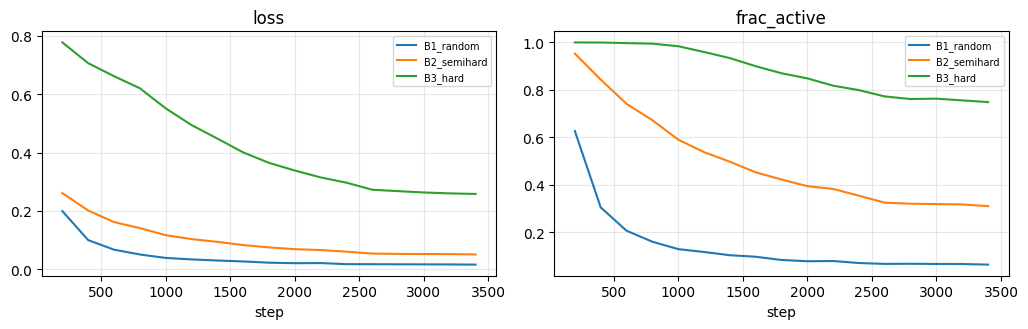

model                             V_F1  V_F1_naive   V_F1_hard   V_F1_rand         AUC         EER      TAR1e2        O_F1 DIR_far1pct           S
A_softmax                       0.6256      0.5537      0.5383      0.7289      0.8744      0.2036      0.2192      0.2412      0.0653      0.4334
B1_random                       0.6722      0.6321      0.5764      0.7872      0.9046      0.1669      0.1921      0.2042      0.0402      0.4382
B2_semihard                     0.7200      0.6960      0.6362      0.8140      0.9289      0.1458      0.3554      0.3288      0.1089      0.5244
B3_hard                         0.6656      0.6175      0.5613      0.7903      0.9009      0.1778      0.2525      0.2688      0.0720      0.4672


In [37]:
for nm, mn in (("B1_random", "random"), ("B2_semihard", "semihard"), ("B3_hard", "hard")):
    run_triplet(nm, mn, keep=True)
BEST = max(["B1_random", "B2_semihard", "B3_hard"], key=lambda n: RESULTS[n]["S"])      # best of the three by S; used in Q5 and Part 6
print("best of B1-B3:", BEST)
plot_hist(["B1_random", "B2_semihard", "B3_hard"]); show_results()

### Q3. Useful triplets
(a) Give a formula for the number of valid triplets in a batch of $P$ identities with $K$ photos and $n_\text{extra}$ distractors, and check it by brute force on one sampled batch.
(b) With the val embeddings of B3, estimate $p_\text{act}$, the probability that a random valid triplet is active at margin 0.3, and the expected number of active triplets per batch under random mining. Compare with the final `frac_active` of B1, B2 and B3.
(c) Rank B1–B3 by S. Does the ranking follow from (b)? Use the `loss` and `frac_active` curves to explain the result of the weakest strategy.
(d) Why does the semi-hard rule fall back to the farthest negative and not the closest? (no code; Schroff et al., 2015, Section 3.2)

In [38]:
n_valid_formula = CFG["P"] * KK * (KK - 1) * ((CFG["P"] - 1) * KK + CFG["n_extra"])   # anchors x positives x negatives
# brute force on one real batch
smp = PKSampler(ytr, CFG["P"], KK, CFG["n_extra"], len(Xdist), seed=1); idx, ex = smp.next()
yb = np.r_[ytr[idx], -1 - np.arange(len(ex))]
same = (yb[:, None] == yb[None, :]) & (yb[:, None] >= 0)
eye = np.eye(len(yb), dtype=bool)
pos, neg = same & ~eye, ~same & ~eye
n_valid_bruteforce = int((pos[:, :, None] & neg[:, None, :]).sum())   # count every valid (a, p, n)
print("(a) formula:", n_valid_formula, "| brute force:", n_valid_bruteforce)

sample_triplets = gx.sample_triplets
Ev3 = EMB["B3_hard"][0]; a, p, q = sample_triplets(V.y, 200000, np.random.default_rng(0))
E3 = l2n(Ev3)
z = ((E3[a] - E3[p]) ** 2).sum(1) - ((E3[a] - E3[q]) ** 2).sum(1) + 0.3
p_act = float((z > 0).mean())                                        # share of random valid triplets that are active
exp_active_random = p_act * CFG["P"] * KK * (KK - 1)                 # random mining: one triplet per (a, p) pair
exp_anchors_hard = CFG["P"] * KK                                     # batch-hard: one triplet per anchor
print(f"(b) p_act = {p_act} | expected active triplets/batch (random mining) = {exp_active_random} | anchors usable by batch-hard <= {CFG['P'] * KK}")
print("    measured frac_active (last log):", {n: round(HIST[n]["frac_active"][-1], 3) for n in ("B1_random", "B2_semihard", "B3_hard")})

(a) formula: 35712 | brute force: 35712
(b) p_act = 0.23276822175473333 | expected active triplets/batch (random mining) = 67.0372478653632 | anchors usable by batch-hard <= 96
    measured frac_active (last log): {'B1_random': 0.065, 'B2_semihard': 0.311, 'B3_hard': 0.749}


**Answer Q3**

(a) …

(b) …

(c) …

(d) …

### 4.4 Experiments B4–B6

- **B4, geometry:** no L2 normalisation, batch-hard, margin 0.3. Evaluated with raw squared L2 (`_rawL2`) and after normalising.
- **B5, margin:** batch-hard, normalised, margins 0.1, 0.3 and 0.9.
- **B6, augmentation:** margin 0.3 with `AUG.clean()` (geometry and mild photometric changes only). Compare with B5 at margin 0.3, which differs only in the augmentation.

[B4_unnormalized] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/B4_unnormalized.pt
[B5_margin0.1] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/B5_margin0.1.pt
[B5_margin0.3] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/B5_margin0.3.pt
[B5_margin0.9] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/B5_margin0.9.pt
[B6_cleanaug] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/B6_cleanaug.pt


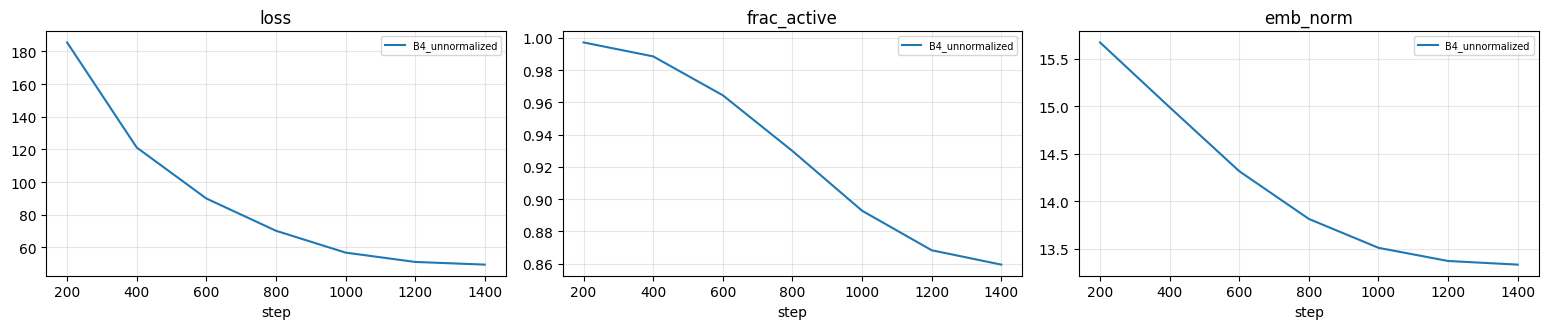

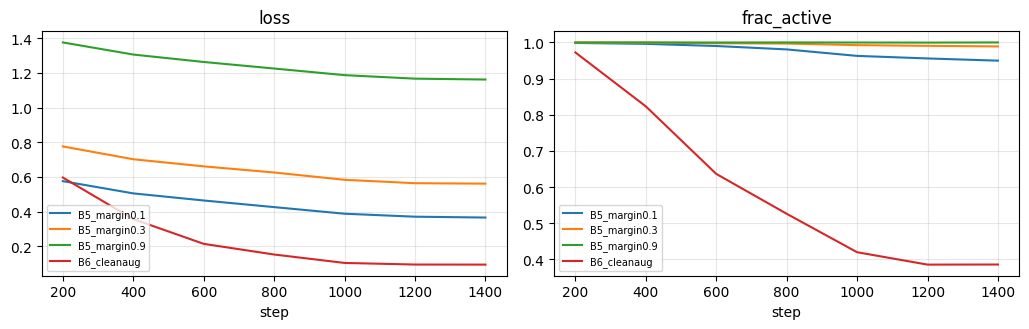

model                             V_F1  V_F1_naive   V_F1_hard   V_F1_rand         AUC         EER      TAR1e2        O_F1 DIR_far1pct           S
B4_unnormalized                 0.5574      0.4734      0.4577      0.6864      0.8364      0.2421      0.1013      0.1408      0.0235      0.3491
B4_unnormalized_rawL2           0.6053      0.5193      0.5154      0.7126      0.8731      0.2140      0.1792      0.1978      0.0536      0.4015
B5_margin0.1                    0.5361      0.4419      0.4389      0.6547      0.8082      0.2742      0.1313      0.1639      0.0302      0.3500
B5_margin0.3                    0.5255      0.4638      0.4335      0.6423      0.8125      0.2651      0.1408      0.1510      0.0402      0.3383
B5_margin0.9                    0.5261      0.4365      0.4267      0.6480      0.8034      0.2742      0.1521      0.1556      0.0452      0.3409
B6_cleanaug                     0.5581      0.4208      0.4873      0.6382      0.8076      0.2692      0.1450      0.

In [39]:
run_triplet("B4_unnormalized", "hard", 0.3, STEPS["geom"], normalize=False)
for mg in (0.1, 0.3, 0.9): run_triplet(f"B5_margin{mg}", "hard", mg, STEPS["margin"])
run_triplet("B6_cleanaug", "hard", 0.3, STEPS["augabl"], aug=AUG.clean())
plot_hist(["B4_unnormalized"], keys=("loss", "frac_active", "emb_norm"))
plot_hist(["B5_margin0.1", "B5_margin0.3", "B5_margin0.9", "B6_cleanaug"], keys=("loss", "frac_active"))
show_results(["B4_unnormalized", "B4_unnormalized_rawL2", "B5_margin0.1", "B5_margin0.3", "B5_margin0.9", "B6_cleanaug"])

### Q4. Gradients, collapse and geometry
(a) From your `analytic_grads`: in which direction does the anchor move, and what happens when $f(p)\approx f(n)$?
(b) Show with a second-order expansion in $\epsilon$ that $f\equiv0$ is a saddle point of the single-triplet loss, and compare with your measured fraction of descent directions.
(c) B4: report `emb_norm` and the loss at the start and at the end of training. Show what happens to $L$ when an unnormalised network scales every embedding by $s$, and use it to explain the B4 loss values. B5: report S for the three margins and explain their spread with `frac_active`.
(d) Give $\|\nabla_p d\|$ for $d=\|a-p\|$ and for $d=\|a-p\|^2$, as $p\to a$ and for a far positive. Which form does your `triplet_loss` use, and what does that mean for a mislabeled positive?

**Answer Q4**

(a) …

(b) …

(c) …

(d) …

### 4.5 Experiments D1–D2: label noise
10 % of the training labels are replaced by a random wrong identity (`flip_labels`). Batch-hard and semi-hard are retrained for the same number of steps as B3 and B2, which serve as the clean references.

In [40]:
ytr_noisy, noisy = flip_labels(ytr, 0.10, seed=123)
print(f"{noisy.sum()} of {len(ytr)} train labels flipped")
run_triplet("D1_hard_noisy", "hard", y=ytr_noisy)
run_triplet("D2_semihard_noisy", "semihard", y=ytr_noisy)
show_results(["B3_hard", "D1_hard_noisy", "B2_semihard", "D2_semihard_noisy"])

564 of 5638 train labels flipped
[D1_hard_noisy] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/D1_hard_noisy.pt
[D2_semihard_noisy] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/D2_semihard_noisy.pt
model                             V_F1  V_F1_naive   V_F1_hard   V_F1_rand         AUC         EER      TAR1e2        O_F1 DIR_far1pct           S
B3_hard                         0.6656      0.6175      0.5613      0.7903      0.9009      0.1778      0.2525      0.2688      0.0720      0.4672
D1_hard_noisy                   0.5292      0.4991      0.4574      0.6195      0.8301      0.2482      0.1733      0.1887      0.0620      0.3590
B2_semihard                     0.7200      0.6960      0.6362      0.8140      0.9289      0.1458      0.3554      0.3288      0.1089      0.5244
D2_semihard_noisy               0.6640      0.5887      0.5840      0.7552      0.8871      0.1908      0.2733      0.2627      0.0737      0.4633


### Q5. Label noise and mining
Let $\epsilon=0.1$ be the share of flipped labels (spread uniformly over the classes) and $K=4$.

(a) Under batch-hard, derive the probability that the hardest positive of an anchor is a false pair (two different people), assuming a foreign photo is always the farthest positive. Derive also the share of false pairs among all anchor–positive pairs.
(b) Implement `false_pair_rates` (embeddings of the train photos from your best model of B1–B3, `BEST`; batches from `PKSampler(y_noisy, ...)`) and compare the measured rates with (a). Which assumption explains a difference?
(c) Report the change of V-F1, AUC and S from B3 to D1 and from B2 to D2. Which strategy loses more, and by which metric? Is this consistent with (a) and Q4(d)?

In [41]:
E_tr_best = embed(MODELS[BEST], Xtr, SZ)
def false_pair_rates(E, y_noisy, y_clean, n_batches=300, seed=0):
    """returns (hardest_positive_is_false_pair rate over anchors, false-pair share among ALL in-batch positive pairs)"""
    smp = PKSampler(y_noisy, CFG["P"], KK, seed=seed)
    E = l2n(np.asarray(E, dtype=np.float64))
    yn_all, yc_all = np.asarray(y_noisy), np.asarray(y_clean)
    hard_false = n_anchor = all_false = n_pairs = 0
    for _ in range(n_batches):
        idx, _ = smp.next()                                       # batch built from the NOISY labels, like training
        Eb, yn, yc = E[idx], yn_all[idx], yc_all[idx]
        D = ((Eb[:, None, :] - Eb[None, :, :]) ** 2).sum(-1)      # distance table
        pos = (yn[:, None] == yn[None, :]) & ~np.eye(len(idx), dtype=bool)   # "positives" according to noisy labels
        false = yc[:, None] != yc[None, :]                        # ...that are really two different people
        hp = np.where(pos, D, -1.0).argmax(1)                     # batch-hard: farthest positive per anchor
        ok = pos.any(1)
        hard_false += int(false[np.arange(len(idx)), hp][ok].sum()); n_anchor += int(ok.sum())
        all_false += int((pos & false).sum()); n_pairs += int(pos.sum())
    return hard_false / max(n_anchor, 1), all_false / max(n_pairs, 1)
eps_ = noisy.mean()
pred_hard = 1 - (1 - eps_) ** KK          # anchor foreign (eps) OR at least one of its K-1 positives foreign
pred_all = 1 - (1 - eps_) ** 2            # a pair is genuine only if BOTH photos are genuine
meas_hard, meas_all = false_pair_rates(E_tr_best, ytr_noisy, ytr)
print(f"batch-hard: predicted {pred_hard} | measured {meas_hard:.3f}      all pairs: predicted {pred_all} | measured {meas_all:.3f}")

batch-hard: predicted 0.3440034348209636 | measured 0.290      all pairs: predicted 0.19006385117156532 | measured 0.177


**Answer Q5**

(a) …

(b) …

(c) …

---
# Part 5. Verification as binary classification

Following slides 24–26, two photos pass through the shared encoder and the pair is classified with
$$h(x_1,x_2)=\sigma\Big(\sum_i w_i\,|f(x_1)_i-f(x_2)_i|+b\Big).$$

### 5.1 Implementation

- `PairHead(dim)`: a module with one `nn.Linear(dim, 1)` named `fc`. `forward(e1, e2)` returns the logit (no sigmoid) and must broadcast: inputs of shape `(n,1,D)` and `(1,K,D)` give `(n,K)`.
- `pair_bce_loss(E, y, head, scheme)`: binary cross-entropy over all in-batch pairs $i<j$ (distractors included, as negatives); the target is "same identity". `scheme="natural"` is the plain mean. `scheme="balanced"` is a weighted mean with weight $n_\text{neg}/n_\text{pos}$ on positive pairs and 1 on negative pairs. Return `(loss, diag)` with `diag["pos_frac"]`, and use the `with_logits` form.

*Figure 7. The pair classifier: a shared encoder and a single linear layer on the absolute difference of the two embeddings.*

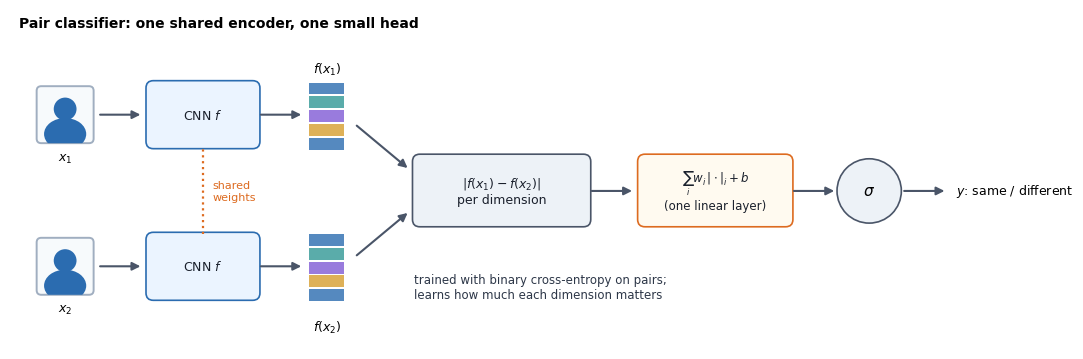

In [42]:
if "gf" in globals(): gf.fig_pair_head()
else: print("Run the setup cell first: it loads the helper modules.")

In [43]:
class PairHead(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.fc = nn.Linear(dim, 1)                              # one weight per embedding dimension + a bias
    def forward(self, e1, e2):
        return self.fc((e1 - e2).abs()).squeeze(-1)              # logit = sum_i w_i |e1_i - e2_i| + b

def pair_bce_loss(E, y, head, scheme="natural"):
    """Returns (loss, diag) with diag['pos_frac']."""
    y = torch.as_tensor(y, device=E.device)
    i, j = torch.triu_indices(len(y), len(y), offset=1, device=E.device)   # every pair i<j in the batch
    logits = head(E[i], E[j])                                    # one logit per pair
    t = ((y[i] == y[j]) & (y[i] >= 0)).float()                   # target: 1 = same real person, 0 = different
    n_pos = t.sum(); n_neg = t.numel() - n_pos
    if scheme == "natural":
        loss = F.binary_cross_entropy_with_logits(logits, t)    # plain mean over all pairs
    elif scheme == "balanced":
        w = torch.where(t > 0, n_neg / n_pos.clamp(min=1), torch.ones_like(t))   # positives weigh n_neg/n_pos
        l = F.binary_cross_entropy_with_logits(logits, t, reduction="none")
        loss = (w * l).sum() / w.sum()                           # weighted mean
    else:
        raise ValueError(f"unknown scheme {scheme!r}")
    return loss, dict(pos_frac=(n_pos / t.numel()).detach())

In [44]:
run_check("pair_head", lambda: gk.check_pair(PairHead, pair_bce_loss))

✔ pair_head


### 5.2 Experiment C
Encoder and head are trained jointly with the balanced scheme. Verification is evaluated with the head's logit and with plain embedding distance. For open-set identification with the head, the logit serves as a negative distance.

In [45]:
bin_model = EmbeddingNet(CFG["backbone"], CFG["emb_dim"], normalize=True).to(DEV)
head = PairHead(CFG["emb_dim"]).to(DEV)
hist_bin = train(bin_model, Xtr, ytr, lambda e, yb: pair_bce_loss(e, yb, head, "balanced"), STEPS["binary"], aug=AUG, P=CFG["P"], K=KK, n_extra=CFG["n_extra"],
                 X_extra=Xdist, extra_modules=[head], name="C_binary", ledger=LEDGER, ckpt_dir=CKPT, seed=SEED, lr=CFG["lr"], log_every=200)
HIST["C_binary"] = hist_bin
Ev_b, Et_b = emb_split(bin_model)

head_logits = lambda Ea, Eb: gx.head_logits(head, Ea, Eb, DEV)
evaluate_model("C_binary_head", Ev_b, Et_b, score_fn=lambda E, i, j: head_logits(E[i], E[j]))
evaluate_model("C_binary_L2", Ev_b, Et_b)

head_openset = lambda E, split: gx.head_openset(head, D, E, split, DEV)
pv_, dv_, tv_ = head_openset(Ev_b, "val"); pt_, dt_, tt_ = head_openset(Et_b, "test")
tau_h = best_open_set_threshold(dv_, pv_, tv_)[0]; oh = open_set_f1(pt_, dt_ <= tau_h, tt_)
print(f"open-set with the head: O-F1 {oh['f1']:.4f} (FAR {oh['far']:.3f}) | with embedding distance: O-F1 {RESULTS['C_binary_L2']['O_F1']:.4f}")
show_results([BEST, "C_binary_head", "C_binary_L2"])

[C_binary] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/C_binary.pt
open-set with the head: O-F1 0.0484 (FAR 0.813) | with embedding distance: O-F1 0.1340
model                             V_F1  V_F1_naive   V_F1_hard   V_F1_rand         AUC         EER      TAR1e2        O_F1 DIR_far1pct           S
B2_semihard                     0.7200      0.6960      0.6362      0.8140      0.9289      0.1458      0.3554      0.3288      0.1089      0.5244
C_binary_head                   0.6765      0.6102      0.6042      0.7605      0.9053      0.1649      0.0950      0.1340      0.0151      0.4052
C_binary_L2                     0.6400      0.5293      0.5569      0.7403      0.8801      0.1842      0.0883      0.1340      0.0151      0.3870


### Q6. The head as a distance
(a) Show that thresholding the logit is the same as thresholding a weighted L1 distance when all $w_i\le0$. Report the fraction of positive $w_i$ and the fraction of val positive and negative pairs whose logit exceeds $z(x,x)=b$. Is your head a distance?
(b) Report the test F1 of the rule "$p\ge0.5$" as is, after `shift_logit` to the test prior, and with the threshold tuned on val. Explain the gap between the first two.
(c) For $K=10^6$ enrolled people and $d=256$: how much memory does the head read per probe, and which of head and cosine similarity can use an approximate nearest-neighbour index? Why? (HNSW: Malkov and Yashunin; FAISS: Johnson et al.)

In [46]:
w = head.fc.weight.detach().cpu().numpy().ravel(); b0 = float(head.fc.bias)
frac_pos_w = float((w > 0).mean())
zv = head_logits(Ev_b[V.pairs.i], Ev_b[V.pairs.j])
frac_pos_above_self = float((zv[V.pairs.y == 1] > b0).mean())     # val positive pairs with z > z(x,x) = b
frac_neg_above_self = float((zv[V.pairs.y == 0] > b0).mean())     # val negative pairs with z > z(x,x) = b
print(f"(a) positive weights: {frac_pos_w} | val positives above z(x,x): {frac_pos_above_self} | negatives above z(x,x): {frac_neg_above_self}")

zt = head_logits(Et_b[T.pairs.i], Et_b[T.pairs.j]); yt = T.pairs.y
f1_p05 = f1_at(zt, yt, 0.0)                                        # p >= 0.5  <=>  logit >= 0
f1_p05_shift = f1_at(shift_logit(zt, 0.5, yt.mean()), yt, 0.0)    # same rule after moving the prior to the test's 20%
print(f"(b) test F1: p>=0.5 as is {f1_p05} | after prior shift {f1_p05_shift} | tuned on val {RESULTS['C_binary_head']['V_F1']:.4f}")

(a) positive weights: 0.49609375 | val positives above z(x,x): 0.567 | negatives above z(x,x): 0.083
(b) test F1: p>=0.5 as is 0.676670239371204 | after prior shift 0.3212101705825555 | tuned on val 0.6765


**Answer Q6**

(a) …

(b) …

(c) …

---
# Part 6. From verification to identification

Comparing a probe with $K$ enrolled people multiplies the chances of a false accept. If one comparison has false-accept rate $f$ and the $K$ comparisons are independent,
$$\text{FAR}_K = 1-(1-f)^K \approx Kf .$$
This part tests how well that holds, using the best model of B1–B3 (`BEST`). Distances are squared L2 on normalised embeddings and the score is $-d$.

### 6.1 Tools

- `tau_at_far(neg_scores, far)`: the smallest score threshold such that at most $\lfloor \text{far}\cdot n\rfloor$ of the negative scores are accepted (accept iff score $\ge$ threshold). The distance threshold is $\tau_d=-\tau_s$.
- `scaling_experiment(E, tau_d, Ks, n_rep, seed)` returns `(far, per_img)`. For every $K$ it draws `n_rep` random test galleries with `gd.sample_gallery`; the stranger FAR is the fraction of stranger probes whose nearest gallery item is within $\tau_d$. `far[K] = (mean, std)`; `per_img[K] = (fa, seen)` counts, per test photo, how often it was falsely accepted and how often it was a stranger probe.

In [47]:
def tau_at_far(neg_scores, far):
    s = np.sort(np.asarray(neg_scores, dtype=np.float64))[::-1]       # negatives, highest score first
    m = int(np.floor(far * len(s) + 1e-9))                            # how many negatives may be accepted
    if m >= len(s):
        return -np.inf                                                # everything may pass
    return float(np.nextafter(s[m], np.inf))                          # just above the (m+1)-th highest negative

def scaling_experiment(E, tau_d, Ks, n_rep=20, seed=0, split="test"):
    rng = np.random.default_rng(seed)
    n_img = len(D[split].y)
    far, per_img = {}, {}
    for K in Ks:
        rates = []
        fa, seen = np.zeros(n_img), np.zeros(n_img)
        for _ in range(n_rep):
            g = gd.sample_gallery(D, split, K, rng)                   # random K members, everyone else = stranger
            strangers = g.probe_idx[g.probe_y < 0]
            _, _, acc = open_set_decide(E[g.gal_idx], E[strangers], tau_d)   # your Part 2 door
            rates.append(acc.mean())                                  # stranger FAR for this gallery
            fa[strangers] += acc                                      # per photo: times falsely accepted
            seen[strangers] += 1                                      # per photo: times it was a stranger probe
        far[K] = (float(np.mean(rates)), float(np.std(rates)))
        per_img[K] = (fa, seen)
    return far, per_img

In [48]:
run_check("scaling_tools", lambda: gk.check_scaling(tau_at_far, scaling_experiment, EMB[BEST][1]))

✔ scaling_tools


### 6.2 Experiment
$\tau_d$ is set at 2 % FAR on all val negative pairs. Three per-comparison false-accept rates are measured at that threshold: `f_all` on all val negative pairs, `f_rand` on the random-tier negatives only, and `f_prot` on the comparisons the protocol actually makes (every non-enrollment val photo and distractor against every val enrollment photo of a different identity).

In [49]:
E3v, E3t = EMB[BEST]
sv3 = pair_scores(E3v, V.pairs.i, V.pairs.j); neg = V.pairs.y == 0
tau_s_all = tau_at_far(sv3[neg], 0.02); tau_d = -tau_s_all
f_all = float((sv3[neg] >= tau_s_all).mean())                              # all val negative pairs
f_rand = float((sv3[neg & (V.pairs.tier == 0)] >= tau_s_all).mean())      # random-tier negatives only
# the comparisons the door really makes: non-enrollment val photos + distractors vs enrollment photos of OTHER people
probe = np.flatnonzero(~V.enroll)
Gv, Pv = E3v[V.all_enroll], E3v[probe]
dd = (Pv ** 2).sum(1)[:, None] + (Gv ** 2).sum(1)[None, :] - 2.0 * Pv @ Gv.T
other = V.y[probe][:, None] != np.arange(len(V.all_enroll))[None, :]      # never compare someone with their own ID photo
f_prot = float((dd[other] <= tau_d).mean())
print(f"tau_d = {tau_d:.3f} | f_all = {f_all} | f_rand = {f_rand} | f_prot = {f_prot}")
Ks = [k for k in (5, 10, 20, 40, 80, 160) if k <= T.n_ids]
far_emp, per_img = scaling_experiment(E3t, tau_d, Ks, n_rep=20, seed=0)
print(f"{'K':>5}{'empirical FAR_K':>18}{'indep(f_all)':>14}{'indep(f_rand)':>15}{'indep(f_prot)':>15}")
for K in Ks:
    ind = lambda f: 1 - (1 - f) ** K
    print(f"{K:>5}{far_emp[K][0]:>12.3f}±{far_emp[K][1]:.3f}{ind(f_all):>14.3f}{ind(f_rand):>15.3f}{ind(f_prot):>15.3f}")

tau_d = 1.095 | f_all = 0.02 | f_rand = 0.004 | f_prot = 0.005320632618337006
    K   empirical FAR_K  indep(f_all)  indep(f_rand)  indep(f_prot)
    5       0.034±0.008         0.096          0.020          0.026
   10       0.062±0.014         0.183          0.039          0.052
   20       0.116±0.017         0.332          0.077          0.101
   40       0.222±0.019         0.554          0.148          0.192
   80       0.367±0.018         0.801          0.274          0.347
  160       0.570±0.013         0.961          0.473          0.574


### Q7. Error compounding
(a) Derive $\text{FAR}_K=1-(1-f)^K$ under independence.
(b) Report `f_all`, `f_rand`, `f_prot` and the $\text{FAR}_K$ table. Which `indep(·)` column matches the empirical values best, and why are the other two off? Does the remaining gap grow with $K$, and what does that say about independence?
(c) Report the share of all false accepts caused by the 5 % of strangers with the highest false-accept rate, and the share of degraded photos among them. Do some photos attract false accepts in your model?
(d) For $\text{FAR}_K\le10^{-2}$ at $K=10^4$: the required $f$, and the number of independent negative comparisons needed to estimate it with 20 % relative standard error. Compare with the number of negative pairs in your test set.

In [50]:
Kmax = Ks[-1]; fa, seen = per_img[Kmax]
ok = seen > 0; rate = fa[ok] / seen[ok]
top = np.argsort(-rate)[: max(1, int(np.ceil(0.05 * ok.sum())))]          # the 5% of stranger photos accepted most often
share_top5 = float(fa[ok][top].sum() / max(fa[ok].sum(), 1))              # their share of ALL false accepts
flags_top = float((T.flags[ok][top] > 0).mean())                          # share of degraded photos among them
print(f"(c) K={Kmax}: top-5% photos cause {share_top5} of the false accepts | degraded share in top-5%: {flags_top} vs overall: {(T.flags[ok] > 0).mean():.3f}")
f_needed = 1 - (1 - 0.01) ** (1 / 1e4)                                    # FAR_K <= 1% at K = 10,000
n_needed = (1 - f_needed) / (0.2 ** 2 * f_needed)                         # binomial: relative SE sqrt((1-f)/(n f)) = 20%
print(f"(d) f needed = {f_needed} | independent negative comparisons needed = {n_needed}")

(c) K=160: top-5% photos cause 0.07187031844197748 of the false accepts | degraded share in top-5%: 0.30201342281879195 vs overall: 0.355
(d) f needed = 1.0050330803146323e-06 | independent negative comparisons needed = 24874778.11809595


**Answer Q7**

(a) …

(b) …

(c) …

(d) …

---
# Part 7. Challenge

Maximise $S=\tfrac12(\text{V-F1}+\text{O-F1})$ on test, with all thresholds chosen on val.

There is one final run, named `E_final`. It may process at most `CH_IMAGES` training images (24,000 steps of 128 images, about 3.1 M); `run_challenge` enforces this. Runs with any other name (pilots) are unrestricted: use a small backbone and a few hundred steps. After each run the peak GPU memory is printed; stay below the memory of your GPU.

**Allowed:** any backbone in `gate_train.ALLOWED_BACKBONES` with ImageNet-1k weights; any loss; sampler settings; your own augmentation (copy and modify `GPUAug`); embedding size; test-time augmentation; score normalisation or calibration fitted on train or val only; distractors as negatives.

**Not allowed:** face-pretrained weights; anything fitted on test labels, test pairs or test images; training on val images; more than `CH_IMAGES` training images for `E_final`.

Resources: Deng et al. (ArcFace), Luo et al. (Bag of Tricks), Musgrave et al. (Metric Learning Reality Check).

In [51]:
FINAL = "E_final"
run_challenge = LAB.run_challenge

### 7.1 Pilots and final run
The cell below starts from the B2 recipe (semi-hard triplet loss). Replace the marked parts. Keep a short log of your pilots.

In [52]:
# ===== Part 7 pilots: building blocks =====
n_cls_tr = int(ytr.max()) + 1          # 1,176 training identities
PILOTS = {}

class MarginHead(nn.Module):
    """CosFace / ArcFace classifier on L2-normalised embeddings (used during training only)."""
    def __init__(self, dim, n_cls, kind="cosface", s=30.0, m=None):
        super().__init__()
        self.W = nn.Parameter(torch.empty(n_cls, dim)); nn.init.xavier_normal_(self.W)   # one "center" per person
        self.kind, self.s = kind, s
        self.m = m if m is not None else (0.35 if kind == "cosface" else 0.5)
    def forward(self, e, y):
        cos = F.linear(F.normalize(e, dim=1), F.normalize(self.W, dim=1)).clamp(-1 + 1e-7, 1 - 1e-7)
        onehot = F.one_hot(y, cos.shape[1]).to(cos.dtype)
        if self.kind == "cosface":                       # cos(theta) - m
            target = cos - self.m
        else:                                            # ArcFace: cos(theta + m)
            sin = torch.sqrt(1.0 - cos ** 2)
            target = cos * math.cos(self.m) - sin * math.sin(self.m)
            target = torch.where(cos > math.cos(math.pi - self.m), target, cos - math.sin(math.pi - self.m) * self.m)
        return self.s * (onehot * target + (1 - onehot) * cos)

def make_combo_loss(head, w_tri=1.0, margin=0.3, mining="semihard", smooth=0.1):
    """margin-softmax on the training people + triplet loss (distractors only ever act as triplet negatives)."""
    def loss_fn(E, y):
        known = y >= 0
        l_cls = F.cross_entropy(head(E[known], y[known]), y[known], label_smoothing=smooth)
        l_tri, d = triplet_loss(E, y, margin, mining)
        loss = l_cls + w_tri * l_tri
        return loss, dict(cls=l_cls.detach(), tri=l_tri.detach(), frac_active=d["frac_active"])
    return loss_fn

def val_scores(model, size):
    """S-like score on VALIDATION only (thresholds tuned and measured on val: optimistic, but fair for comparing pilots)."""
    Ev = l2n(embed(model, Xva, size))
    s, y = pair_scores(Ev, V.pairs.i, V.pairs.j), V.pairs.y
    vf1 = f1_sweep(s, y, neg_weights(y, D.meta.test_prevalence))["best_f1"]      # reweighted to 20% matches, like the scoreboard
    o = V.os
    pidx, dmin, _ = open_set_decide(Ev[o.gal_idx], Ev[o.probe_idx], 0.0)
    _, of1 = best_open_set_threshold(dmin, o.gal_y[pidx], o.probe_y)
    return dict(V_F1=round(vf1, 4), O_F1=round(of1, 4), S=round((vf1 + of1) / 2, 4), AUC=round(roc_metrics(s, y)["auc"], 4))

def pilot(name, backbone="resnet50", size=128, steps=4000, kind="cosface", w_tri=1.0, aug_kind="default",
          emb_dim=512, P=24, K=4, n_extra=32, lr=3e-4):
    aug = ga.GPUAug(size)
    if aug_kind == "clean": aug = aug.clean()
    model = EmbeddingNet(backbone, emb_dim, normalize=True).to(DEV)
    head = MarginHead(emb_dim, n_cls_tr, kind=kind).to(DEV)
    train(model, Xtr, ytr, make_combo_loss(head, w_tri), steps, aug=aug, P=P, K=K, n_extra=n_extra, X_extra=Xdist,
          extra_modules=[head], name=name, ledger=LEDGER, ckpt_dir=CKPT, seed=SEED, lr=lr, log_every=500)
    PILOTS[name] = dict(backbone=backbone, size=size, steps=steps, loss=f"{kind}+{w_tri}*triplet", aug=aug_kind,
                        **val_scores(model, size))
    print(name, PILOTS[name])
    return model

def show_pilots():
    for n, r in sorted(PILOTS.items(), key=lambda kv: -kv[1]["S"]):
        print(f"{n:<26} {r}")

In [53]:
REF = val_scores(MODELS["B2_semihard"], CFG["size"])   # your current best, scored the same way
print("reference B2_semihard (val):", REF)

pilot("P1_cos_tri_r50", kind="cosface", w_tri=1.0)    # CosFace + semi-hard triplet
pilot("P2_arc_tri_r50", kind="arcface", w_tri=1.0)    # ArcFace + semi-hard triplet
pilot("P3_cos_only_r50", kind="cosface", w_tri=0.0)   # CosFace alone: does the triplet part help?
show_pilots()

reference B2_semihard (val): {'V_F1': 0.707, 'O_F1': 0.3734, 'S': 0.5402, 'AUC': 0.9101}
[P1_cos_tri_r50] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/P1_cos_tri_r50.pt
P1_cos_tri_r50 {'backbone': 'resnet50', 'size': 128, 'steps': 4000, 'loss': 'cosface+1.0*triplet', 'aug': 'default', 'V_F1': 0.6122, 'O_F1': 0.3227, 'S': 0.4674, 'AUC': 0.843}
[P2_arc_tri_r50] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/P2_arc_tri_r50.pt
P2_arc_tri_r50 {'backbone': 'resnet50', 'size': 128, 'steps': 4000, 'loss': 'arcface+1.0*triplet', 'aug': 'default', 'V_F1': 0.6117, 'O_F1': 0.3235, 'S': 0.4676, 'AUC': 0.8435}
[P3_cos_only_r50] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/P3_cos_only_r50.pt
P3_cos_only_r50 {'backbone': 'resnet50', 'size': 128, 'steps': 4000, 'loss': 'cosface+0.0*triplet', 'aug': 'default', 'V_F1': 0.609, 'O_F1': 0.306, 'S': 0.4575, 'AUC': 0.8403}
P2_arc_tri_r50             {'backbone': 'resnet50', 'size': 128, 'steps': 4000, 'lo

In [54]:
# ===== round 2: semi-hard triplet as the base, change one thing at a time =====
def pilot2(name, backbone="resnet50", emb_dim=256, steps=4000, margin=0.3, mining="semihard",
           aug_kind="default", w_cls=0.0, size=128):
    aug = ga.GPUAug(size)
    if aug_kind == "clean": aug = aug.clean()
    model = EmbeddingNet(backbone, emb_dim, normalize=True).to(DEV)
    mods = []
    if w_cls > 0:
        head = MarginHead(emb_dim, n_cls_tr, kind="cosface").to(DEV); mods = [head]
        def loss_fn(E, y):
            l_tri, d = triplet_loss(E, y, margin, mining)
            known = y >= 0
            l_cls = F.cross_entropy(head(E[known], y[known]), y[known], label_smoothing=0.1)
            return l_tri + w_cls * l_cls, dict(tri=l_tri.detach(), cls=l_cls.detach(), frac_active=d["frac_active"])
    else:
        loss_fn = lambda E, y: triplet_loss(E, y, margin, mining)
    train(model, Xtr, ytr, loss_fn, steps, aug=aug, P=CFG["P"], K=CFG["K"], n_extra=CFG["n_extra"], X_extra=Xdist,
          extra_modules=mods, name=name, ledger=LEDGER, ckpt_dir=CKPT, seed=SEED, lr=CFG["lr"], log_every=1000)
    PILOTS[name] = dict(backbone=backbone, emb=emb_dim, steps=steps, margin=margin, aug=aug_kind, w_cls=w_cls,
                        **val_scores(model, size))
    print(name, PILOTS[name])
    del model; torch.cuda.empty_cache()

pilot2("T1_r50")                                  # base: semi-hard triplet, ResNet-50
pilot2("T2_convnext", backbone="convnext_tiny")   # backbone
pilot2("T3_r101", backbone="resnet101")           # backbone
pilot2("T4_r50_clean", aug_kind="clean")          # augmentation
pilot2("T5_r50_emb512", emb_dim=512)              # embedding size
pilot2("T6_r50_cos0.1", w_cls=0.1)                # triplet + light CosFace
pilot2("T7_r50_8k", steps=8000)                   # longer training
show_pilots()

[T1_r50] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/T1_r50.pt
T1_r50 {'backbone': 'resnet50', 'emb': 256, 'steps': 4000, 'margin': 0.3, 'aug': 'default', 'w_cls': 0.0, 'V_F1': 0.7094, 'O_F1': 0.3669, 'S': 0.5382, 'AUC': 0.9159}
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 171MB/s]  


[T2_convnext] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/T2_convnext.pt
T2_convnext {'backbone': 'convnext_tiny', 'emb': 256, 'steps': 4000, 'margin': 0.3, 'aug': 'default', 'w_cls': 0.0, 'V_F1': 0.7695, 'O_F1': 0.4852, 'S': 0.6274, 'AUC': 0.9445}
Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:00<00:00, 271MB/s] 


[T3_r101] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/T3_r101.pt
T3_r101 {'backbone': 'resnet101', 'emb': 256, 'steps': 4000, 'margin': 0.3, 'aug': 'default', 'w_cls': 0.0, 'V_F1': 0.7528, 'O_F1': 0.4064, 'S': 0.5796, 'AUC': 0.9266}
[T4_r50_clean] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/T4_r50_clean.pt
T4_r50_clean {'backbone': 'resnet50', 'emb': 256, 'steps': 4000, 'margin': 0.3, 'aug': 'clean', 'w_cls': 0.0, 'V_F1': 0.5868, 'O_F1': 0.3162, 'S': 0.4515, 'AUC': 0.8183}
[T5_r50_emb512] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/T5_r50_emb512.pt
T5_r50_emb512 {'backbone': 'resnet50', 'emb': 512, 'steps': 4000, 'margin': 0.3, 'aug': 'default', 'w_cls': 0.0, 'V_F1': 0.7296, 'O_F1': 0.3959, 'S': 0.5628, 'AUC': 0.9136}
[T6_r50_cos0.1] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/T6_r50_cos0.1.pt
T6_r50_cos0.1 {'backbone': 'resnet50', 'emb': 256, 'steps': 4000, 'margin': 0.3, 'aug': 'default', 'w_cls': 0.1, 'V

In [55]:
# ===== round 3: the COMBINATION of round-2 winners, margin tuning, and a longer-training check =====
R2 = ["T1_r50", "T2_convnext", "T3_r101", "T4_r50_clean", "T5_r50_emb512", "T6_r50_cos0.1"]
base = PILOTS["T1_r50"]["S"]; better = lambda n: PILOTS[n]["S"] > base + 0.005
bb = max(R2[:3], key=lambda n: PILOTS[n]["S"])
combo = dict(backbone=PILOTS[bb]["backbone"],
             emb_dim=512 if better("T5_r50_emb512") else 256,
             aug_kind="clean" if better("T4_r50_clean") else "default",
             w_cls=0.1 if better("T6_r50_cos0.1") else 0.0,
             margin=0.3)
rname = lambda c: f"R3_{c['backbone']}_e{c['emb_dim']}_{c['aug_kind']}_c{c['w_cls']}_m{c['margin']}"
options = {}
for c in (combo, dict(combo, margin=0.2), dict(combo, margin=0.4)):      # the combination, with 3 margins
    if rname(c) not in PILOTS: pilot2(rname(c), **c)
    options[rname(c)] = c
r2best = max(R2, key=lambda n: PILOTS[n]["S"])                           # the best single change from round 2
p = PILOTS[r2best]
options[r2best] = dict(backbone=p["backbone"], emb_dim=p["emb"], aug_kind=p["aug"], w_cls=p["w_cls"], margin=p["margin"])
RECIPE_NAME = max(options, key=lambda n: PILOTS[n]["S"])
RECIPE = options[RECIPE_NAME]

# longer-training check on the winner: 12,000 steps vs 4,000
long_name = RECIPE_NAME + "_12k"
if long_name not in PILOTS: pilot2(long_name, steps=12000, **RECIPE)
STEPS_FINAL = STEPS["challenge"] if PILOTS[long_name]["S"] >= PILOTS[RECIPE_NAME]["S"] else 12000

show_pilots()
print("\nchosen for E_final:", RECIPE_NAME, RECIPE, "| steps:", STEPS_FINAL)

[R3_convnext_tiny_e512_default_c0.0_m0.3] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/R3_convnext_tiny_e512_default_c0.0_m0.3.pt
R3_convnext_tiny_e512_default_c0.0_m0.3 {'backbone': 'convnext_tiny', 'emb': 512, 'steps': 4000, 'margin': 0.3, 'aug': 'default', 'w_cls': 0.0, 'V_F1': 0.7715, 'O_F1': 0.4817, 'S': 0.6266, 'AUC': 0.9436}
[R3_convnext_tiny_e512_default_c0.0_m0.2] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/R3_convnext_tiny_e512_default_c0.0_m0.2.pt
R3_convnext_tiny_e512_default_c0.0_m0.2 {'backbone': 'convnext_tiny', 'emb': 512, 'steps': 4000, 'margin': 0.2, 'aug': 'default', 'w_cls': 0.0, 'V_F1': 0.776, 'O_F1': 0.4727, 'S': 0.6243, 'AUC': 0.9466}
[R3_convnext_tiny_e512_default_c0.0_m0.4] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/R3_convnext_tiny_e512_default_c0.0_m0.4.pt
R3_convnext_tiny_e512_default_c0.0_m0.4 {'backbone': 'convnext_tiny', 'emb': 512, 'steps': 4000, 'margin': 0.4, 'aug': 'default', 'w_cls': 0.0, 'V

In [56]:
# ===== how long should E_final train? compare 4k / 6k / 8k / 12k on validation =====
for st in (6000, 8000):
    n = f"{RECIPE_NAME}_{st // 1000}k"
    if n not in PILOTS: pilot2(n, steps=st, **RECIPE)
lengths = {4000: PILOTS[RECIPE_NAME]["S"], 6000: PILOTS[f"{RECIPE_NAME}_6k"]["S"],
           8000: PILOTS[f"{RECIPE_NAME}_8k"]["S"], 12000: PILOTS[f"{RECIPE_NAME}_12k"]["S"]}
STEPS_FINAL = max(lengths, key=lengths.get)
print("val S by training length:", lengths, "-> E_final steps:", STEPS_FINAL)

[R3_convnext_tiny_e512_default_c0.0_m0.4_6k] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/R3_convnext_tiny_e512_default_c0.0_m0.4_6k.pt
R3_convnext_tiny_e512_default_c0.0_m0.4_6k {'backbone': 'convnext_tiny', 'emb': 512, 'steps': 6000, 'margin': 0.4, 'aug': 'default', 'w_cls': 0.0, 'V_F1': 0.7773, 'O_F1': 0.4875, 'S': 0.6324, 'AUC': 0.9435}
[R3_convnext_tiny_e512_default_c0.0_m0.4_8k] loaded cached checkpoint /content/drive/MyDrive/cmps364_a4/ckpt/R3_convnext_tiny_e512_default_c0.0_m0.4_8k.pt
R3_convnext_tiny_e512_default_c0.0_m0.4_8k {'backbone': 'convnext_tiny', 'emb': 512, 'steps': 8000, 'margin': 0.4, 'aug': 'default', 'w_cls': 0.0, 'V_F1': 0.7852, 'O_F1': 0.4892, 'S': 0.6372, 'AUC': 0.94}
val S by training length: {4000: 0.6333, 6000: 0.6324, 8000: 0.6372, 12000: 0.6122} -> E_final steps: 8000


In [59]:
# ===== round 4: generalization tricks + one backbone challenger (each vs the round-3 winner, then combined) =====
import inspect
print(inspect.getsource(LAB.run_challenge))        # so we can see which settings run_challenge accepts

class EraseAug:
    """Wraps an augmentation and blanks out one random rectangle per image (random erasing)."""
    def __init__(self, base, p=0.5, area=(0.02, 0.2), ratio=(0.3, 3.3)):
        self.base, self.p, self.area, self.ratio = base, p, area, ratio
    def __call__(self, x):
        x = self.base(x)
        B, C, H, W = x.shape; dev = x.device
        a = torch.empty(B, device=dev).uniform_(*self.area) * H * W                    # area of each box
        r = torch.exp(torch.empty(B, device=dev).uniform_(math.log(self.ratio[0]), math.log(self.ratio[1])))
        h = (a * r).sqrt().clamp(1, H - 1).floor(); w = (a / r).sqrt().clamp(1, W - 1).floor()
        y0 = (torch.rand(B, device=dev) * (H - h)).floor(); x0 = (torch.rand(B, device=dev) * (W - w)).floor()
        ys = torch.arange(H, device=dev)[None, :, None]; xs = torch.arange(W, device=dev)[None, None, :]
        box = ((ys >= y0[:, None, None]) & (ys < (y0 + h)[:, None, None]) &
               (xs >= x0[:, None, None]) & (xs < (x0 + w)[:, None, None]) & (torch.rand(B, device=dev) < self.p)[:, None, None])
        return x.masked_fill(box[:, None], 0)

def pilot3(name, backbone, emb_dim, margin, steps=4000, size=128, P=CFG["P"], K=CFG["K"],
           n_extra=CFG["n_extra"], wd=1e-4, erase=0.0, **_):
    aug = ga.GPUAug(size)
    if erase > 0: aug = EraseAug(aug, p=erase)
    model = EmbeddingNet(backbone, emb_dim, normalize=True).to(DEV)
    train(model, Xtr, ytr, lambda E, y: triplet_loss(E, y, margin, "semihard"), steps, aug=aug, P=P, K=K,
          n_extra=n_extra, X_extra=Xdist, wd=wd, name=name, ledger=LEDGER, ckpt_dir=CKPT, seed=SEED,
          lr=CFG["lr"], log_every=2000)
    PILOTS[name] = dict(backbone=backbone, emb=emb_dim, margin=margin, size=size, P=P, K=K, n_extra=n_extra,
                        wd=wd, erase=erase, steps=steps, **val_scores(model, size))
    print(name, PILOTS[name])
    del model; torch.cuda.empty_cache()

R4_base = dict(backbone=RECIPE["backbone"], emb_dim=RECIPE["emb_dim"], margin=RECIPE["margin"])
R4_changes = {
    "R4_regnet":   dict(backbone="regnet_y_3_2gf"),   # backbone challenger
    "R4_erase":    dict(erase=0.5),                    # random erasing
    "R4_K3P32":    dict(P=32, K=3),                     # fewer duplicate positives, more people per batch
    "R4_dist64":   dict(n_extra=64),                    # more stranger negatives
    "R4_wd05":     dict(wd=0.05),                       # stronger weight decay
    "R4_s160":     dict(size=160),                      # larger images
}
for n, ch in R4_changes.items():
    if n not in PILOTS: pilot3(n, **{**R4_base, **ch})

base_S = PILOTS[RECIPE_NAME]["S"]
winners = [n for n in R4_changes if PILOTS[n]["S"] > base_S + 0.01]          # 0.01 margin against noise
print("\nround-4 base S:", base_S, "| changes that beat it:", winners)
options4 = {RECIPE_NAME: dict(R4_base)}
for n in winners: options4[n] = {**R4_base, **R4_changes[n]}
if len(winners) >= 2:                                                          # test all winners TOGETHER
    combo4 = dict(R4_base)
    for n in winners: combo4.update(R4_changes[n])
    if "R4_combo" not in PILOTS: pilot3("R4_combo", **combo4)
    options4["R4_combo"] = combo4
RECIPE4_NAME = max(options4, key=lambda n: PILOTS[n]["S"])
RECIPE4 = options4[RECIPE4_NAME]
show_pilots()
print("\nround-4 choice:", RECIPE4_NAME, RECIPE4)

    def run_challenge(self, name, model, loss_fn, steps, aug=None, extra_modules=(), y=None, P=None, K=None, n_extra=None, lr=None, normalize=True, **kw):
        c = self.cfg
        P_, K_, X_ = P or c["P"], K or c["K"], c["n_extra"] if n_extra is None else n_extra
        batch = P_ * K_ + X_
        if name == self.final and steps * batch > self.ch_images * 1.0001:
            raise ValueError(f"final run: {steps} steps x {batch} images = {steps * batch:,} > budget CH_IMAGES = {self.ch_images:,}")
        print(f"{name}: {steps} steps x {batch} images = {steps * batch / 1e6:.2f} M images (budget {self.ch_images / 1e6:.2f} M)")
        h = train(model, self.Xtr, self.ytr if y is None else y, loss_fn, steps, aug=aug or self.aug, P=P_, K=K_, n_extra=X_, X_extra=self.Xdist, extra_modules=extra_modules,
                  name=name, ledger=self.ledger, ckpt_dir=self.ckpt, seed=self.seed, lr=lr or c["lr"], log_every=200, **kw)
        self.hist[name] = h
        Ev, Et = self.emb_split(mo

In [60]:
# ===== round 5a: resolution, length, and a second seed (ensemble partner), all on the round-4 recipe =====
MODELS5 = {}
def train_keep(name, backbone, emb_dim, margin, steps=4000, size=160, P=32, K=3, n_extra=32, wd=1e-4, seed=None, **_):
    """train (or reload from its checkpoint) and KEEP the model in memory"""
    model = EmbeddingNet(backbone, emb_dim, normalize=True).to(DEV)
    train(model, Xtr, ytr, lambda E, y: triplet_loss(E, y, margin, "semihard"), steps, aug=ga.GPUAug(size),
          P=P, K=K, n_extra=n_extra, X_extra=Xdist, wd=wd, name=name, ledger=LEDGER, ckpt_dir=CKPT,
          seed=SEED if seed is None else seed, lr=CFG["lr"], log_every=2000)
    model.eval(); MODELS5[name] = model
    if name not in PILOTS:
        PILOTS[name] = dict(backbone=backbone, emb=emb_dim, margin=margin, size=size, P=P, K=K, n_extra=n_extra,
                            wd=wd, steps=steps, seed=seed, **val_scores(model, size))
    print(name, PILOTS[name]); return model

R5 = dict(RECIPE4)                                         # convnext_tiny, 512, margin 0.4, P=32, K=3, 160 px
train_keep("R4_combo", **R5)                               # reloads the round-4 winner (no retraining)
train_keep("R5_s192", **{**R5, "size": 192})               # higher resolution
train_keep("R5_s224", **{**R5, "size": 224})               # ImageNet's native resolution
train_keep("R5_combo_8k", **{**R5, "steps": 8000})         # length check for the new recipe
train_keep("R5_combo_seed2", **{**R5, "seed": SEED + 1})   # same recipe, other seed -> ensemble partner

[R4_combo] step  2000/4000 | frac_active 0.5512 | loss 0.1368 | emb_norm 1
[R4_combo] step  4000/4000 | frac_active 0.2453 | loss 0.04274 | emb_norm 1
R4_combo {'backbone': 'convnext_tiny', 'emb': 512, 'margin': 0.4, 'size': 160, 'P': 32, 'K': 3, 'n_extra': 32, 'wd': 0.0001, 'steps': 4000, 'seed': None, 'V_F1': 0.7876, 'O_F1': 0.5143, 'S': 0.651, 'AUC': 0.953}
[R5_s192] step  2000/4000 | frac_active 0.5226 | loss 0.1267 | emb_norm 1
[R5_s192] step  4000/4000 | frac_active 0.2185 | loss 0.03644 | emb_norm 1
R5_s192 {'backbone': 'convnext_tiny', 'emb': 512, 'margin': 0.4, 'size': 192, 'P': 32, 'K': 3, 'n_extra': 32, 'wd': 0.0001, 'steps': 4000, 'seed': None, 'V_F1': 0.8002, 'O_F1': 0.4894, 'S': 0.6448, 'AUC': 0.956}
[R5_s224] step  2000/4000 | frac_active 0.5009 | loss 0.12 | emb_norm 1
[R5_s224] step  4000/4000 | frac_active 0.1971 | loss 0.03189 | emb_norm 1
R5_s224 {'backbone': 'convnext_tiny', 'emb': 512, 'margin': 0.4, 'size': 224, 'P': 32, 'K': 3, 'n_extra': 32, 'wd': 0.0001, 'step

EmbeddingNet(
  (backbone): ConvNeXt(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
        (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True, bias=True)
      )
      (1): Sequential(
        (0): CNBlock(
          (block): Sequential(
            (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
            (1): Permute()
            (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
            (3): Linear(in_features=96, out_features=384, bias=True)
            (4): GELU(approximate='none')
            (5): Linear(in_features=384, out_features=96, bias=True)
            (6): Permute()
          )
          (stochastic_depth): StochasticDepth(p=0.0, mode=row)
        )
        (1): CNBlock(
          (block): Sequential(
            (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
            (1): Permute()
        

In [61]:
# ===== round 5b: multi-scale TTA, ensemble, within-class whitening (all scored on VALIDATION) =====
def s_from(Ev):
    Ev = l2n(Ev); s, y = pair_scores(Ev, V.pairs.i, V.pairs.j), V.pairs.y
    vf1 = f1_sweep(s, y, neg_weights(y, D.meta.test_prevalence))["best_f1"]
    o = V.os; pidx, dmin, _ = open_set_decide(Ev[o.gal_idx], Ev[o.probe_idx], 0.0)
    _, of1 = best_open_set_threshold(dmin, o.gal_y[pidx], o.probe_y)
    return round((vf1 + of1) / 2, 4)

def emb_tta(m, X, sizes):                       # average over sizes (each embed() already includes the mirror image)
    return l2n(sum(l2n(embed(m, X, s)) for s in sizes))
def emb_ens(models, X, sizes):                  # ensemble = concatenation of the members' embeddings
    return l2n(np.concatenate([emb_tta(m, X, sizes) for m in models], 1))

def train_aug_emb(models, size, n_pass=2):      # embeddings of AUGMENTED training photos (train data only)
    aug, out, labs = ga.GPUAug(size), [], []
    with torch.no_grad():
        for _ in range(n_pass):
            for s in range(0, len(ytr), 256):
                xb = aug(Xtr[s:s + 256]); parts = []
                for m in models:
                    with torch.autocast("cuda", dtype=torch.float16):
                        e = m(xb).float() + m(torch.flip(xb, dims=[3])).float()
                    parts.append(F.normalize(e, dim=1))
                out.append(F.normalize(torch.cat(parts, 1), dim=1).cpu().numpy()); labs.append(ytr[s:s + 256])
    return np.concatenate(out).astype(np.float64), np.concatenate(labs)
def fit_wccn(F_, L_):                           # global mean + within-class covariance
    m = F_.mean(0); Sw = np.zeros((F_.shape[1],) * 2)
    for c in np.unique(L_):
        Xc = F_[L_ == c]; Xc = Xc - Xc.mean(0); Sw += Xc.T @ Xc
    return m, Sw / len(F_)
def whiten(E, m, Sw, alpha):                    # shrink the within-person directions (alpha = regularisation)
    d = Sw.shape[0]; vals, vecs = np.linalg.eigh(Sw + alpha * np.trace(Sw) / d * np.eye(d))
    return l2n((E - m) @ (vecs / np.sqrt(vals)) @ vecs.T)

# 1) best single model and training length
singles = ["R4_combo", "R5_s192", "R5_s224"]
best_n = max(singles, key=lambda n: PILOTS[n]["S"]); bm = MODELS5[best_n]; size = PILOTS[best_n]["size"]
steps = 8000 if PILOTS["R5_combo_8k"]["S"] > PILOTS["R4_combo"]["S"] + 0.005 else 4000
print("best single:", best_n, PILOTS[best_n]["S"], "| steps:", steps)
# 2) multi-scale TTA
tta = {tuple(sz): s_from(emb_tta(bm, Xva, sz)) for sz in ([size], [size - 16, size], [size, size + 32], [size - 16, size, size + 32])}
print("TTA:", tta)
sizes = list(max(tta, key=tta.get)); S_tta = tta[tuple(sizes)]
if S_tta < tta[(size,)] + 0.005: sizes, S_tta = [size], tta[(size,)]
# 3) ensemble gain (two seeds of the 160 px recipe)
pair = [MODELS5["R4_combo"], MODELS5["R5_combo_seed2"]]
S_one, S_two = s_from(emb_tta(pair[0], Xva, [160])), s_from(emb_ens(pair, Xva, [160]))
print(f"ensemble: 1 model {S_one} -> 2 models {S_two}")
batch = R5["P"] * R5["K"] + 32
members = min(3, int(CH_IMAGES // (steps * batch))) if S_two > S_one + 0.005 else 1
# 4) within-class whitening (fitted on augmented TRAIN embeddings)
Ftr, Ltr = train_aug_emb([bm], size); mW, SwW = fit_wccn(Ftr, Ltr)
Ev_b = emb_tta(bm, Xva, sizes)
wh = {a: s_from(whiten(Ev_b, mW, SwW, a)) for a in (0.1, 0.3, 1.0, 3.0)}
print("whitening:", wh, "| without:", S_tta)
alpha = max(wh, key=wh.get) if max(wh.values()) > S_tta + 0.005 else None

PLAN = dict(backbone=R5["backbone"], emb_dim=R5["emb_dim"], margin=R5["margin"], P=R5["P"], K=R5["K"], n_extra=32,
            size=size, steps=steps, members=members, sizes=sizes, alpha=alpha)
print("\nPLAN:", PLAN)
PLAN["members"] = 1          # single model: the notebook allows "one final run" and does not mention ensembles

best single: R4_combo 0.651 | steps: 4000
TTA: {(160,): 0.651, (144, 160): 0.6563, (160, 192): 0.6471, (144, 160, 192): 0.6552}
ensemble: 1 model 0.651 -> 2 models 0.6576
whitening: {0.1: 0.6237, 0.3: 0.6331, 1.0: 0.6432, 3.0: 0.6472} | without: 0.6563

PLAN: {'backbone': 'convnext_tiny', 'emb_dim': 512, 'margin': 0.4, 'P': 32, 'K': 3, 'n_extra': 32, 'size': 160, 'steps': 4000, 'members': 3, 'sizes': [144, 160], 'alpha': None}


In [63]:
# ---------------- YOUR FINAL CONFIGURATION ----------------
# A copy of LAB.run_challenge (allowed in Part 7): same budget check, training, evaluation and log,
# extended to train at the chosen image size and to embed val/test at that size.
# Every choice in PLAN was made on validation in pilot rounds 1-5 (see the pilot log).
CH = dict(backbone="convnext_tiny", emb_dim=512, margin=0.4, P=32, K=3, n_extra=32,      # frozen: the recipe chosen
          size=160, steps=4000, members=1, sizes=[160], alpha=None)                     # by pilot rounds 1-5 (PLAN)
if {k: PLAN[k] for k in CH} != CH: print("note: this re-run's PLAN differs from the frozen recipe:", PLAN)
print("final plan:", CH)
batch = CH["P"] * CH["K"] + CH["n_extra"]
total = CH["members"] * CH["steps"] * batch
assert total <= CH_IMAGES * 1.0001, f"budget exceeded: {total:,} > {CH_IMAGES:,}"
print(f"{FINAL}: {CH['members']} member(s) x {CH['steps']} steps x {batch} images = {total / 1e6:.2f} M images (budget {CH_IMAGES / 1e6:.2f} M)")
members, peak = [], 0.0
for i in range(CH["members"]):
    nm = FINAL if i == 0 else f"{FINAL}_m{i}"
    m = EmbeddingNet(CH["backbone"], CH["emb_dim"], normalize=True).to(DEV)
    h = train(m, Xtr, ytr, lambda E, y: triplet_loss(E, y, CH["margin"], "semihard"), CH["steps"],
              aug=ga.GPUAug(CH["size"]), P=CH["P"], K=CH["K"], n_extra=CH["n_extra"], X_extra=Xdist,
              name=nm, ledger=LEDGER, ckpt_dir=CKPT, seed=SEED + i, lr=CFG["lr"], log_every=1000)
    m.eval(); members.append(m); peak = max(peak, h.get("peak_gb", 0.0))
    if i == 0: LAB.hist[FINAL] = h
Ev, Et = emb_ens(members, Xva, CH["sizes"]), emb_ens(members, Xte, CH["sizes"])
if CH["alpha"] is not None:
    Ftr, Ltr = train_aug_emb(members, CH["size"]); mW, SwW = fit_wccn(Ftr, Ltr)          # TRAIN data only
    Ev, Et = whiten(Ev, mW, SwW, CH["alpha"]), whiten(Et, mW, SwW, CH["alpha"])
LAB.board.evaluate(FINAL, Ev, Et, normalize=True)                                           # thresholds on val, scores on test
LAB.chal_log[FINAL] = dict(steps=CH["steps"] * CH["members"], images=total, peak_gb=peak)   # all training images counted
r = LAB.board.results[FINAL]
print(f"{FINAL}: S = {r['S']:.4f}  (V-F1 {r['V_F1']:.4f}, O-F1 {r['O_F1']:.4f})")

note: this re-run's PLAN differs from the frozen recipe: {'backbone': 'convnext_tiny', 'emb_dim': 512, 'margin': 0.4, 'P': 32, 'K': 3, 'n_extra': 32, 'size': 160, 'steps': 4000, 'members': 1, 'sizes': [144, 160], 'alpha': None}
final plan: {'backbone': 'convnext_tiny', 'emb_dim': 512, 'margin': 0.4, 'P': 32, 'K': 3, 'n_extra': 32, 'size': 160, 'steps': 4000, 'members': 1, 'sizes': [160], 'alpha': None}
E_final: 1 member(s) x 4000 steps x 128 images = 0.51 M images (budget 3.07 M)
[E_final] step  1000/4000 | frac_active 0.6913 | loss 0.189 | emb_norm 1
[E_final] step  2000/4000 | frac_active 0.4082 | loss 0.08317 | emb_norm 1
[E_final] step  3000/4000 | frac_active 0.2681 | loss 0.04743 | emb_norm 1
[E_final] step  4000/4000 | frac_active 0.215 | loss 0.03642 | emb_norm 1
E_final: S = 0.6231  (V-F1 0.7944, O-F1 0.4517)


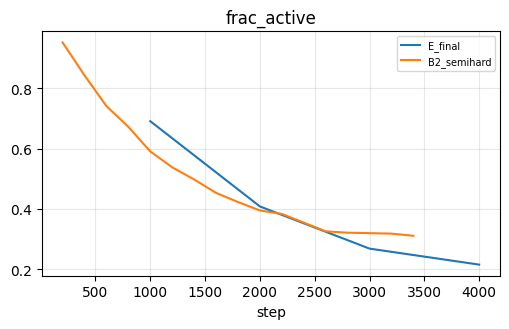

model                             V_F1  V_F1_naive   V_F1_hard   V_F1_rand         AUC         EER      TAR1e2        O_F1 DIR_far1pct           S
A_softmax                       0.6256      0.5537      0.5383      0.7289      0.8744      0.2036      0.2192      0.2412      0.0653      0.4334
B2_semihard                     0.7200      0.6960      0.6362      0.8140      0.9289      0.1458      0.3554      0.3288      0.1089      0.5244
C_binary_head                   0.6765      0.6102      0.6042      0.7605      0.9053      0.1649      0.0950      0.1340      0.0151      0.4052
E_final                         0.7944      0.7376      0.7395      0.8544      0.9556      0.1115      0.5267      0.4517      0.2680      0.6231


In [64]:
plot_hist([FINAL, BEST], keys=("frac_active",)) if FINAL in HIST else None
show_results(["A_softmax", BEST, "C_binary_head", FINAL])

**Pilot log**

| run | what changed | S |
|---|---|---|
| … | … | … |

What the final run keeps from the pilots, in one sentence: …

### Q8. Effect of the degradations
(a) Report the `category_report` table (test pairs with 0, 1 or 2 degraded photos: AUC, V-F1 at your val threshold, mean score of positive and of negative pairs) for your final model.
(b) Which of the two mean scores changes more with the degradation? Give the mechanism and one supporting number (for example the mean cosine similarity between embeddings of different people, degraded versus clean).
(c) Propose one fix that uses no test information, choose its setting on val, and report val and test results before and after (score normalisation: Auckenthaler et al., 2000).
(d) Compare `B6_cleanaug` with `B5_margin0.3`, which differ only in the augmentation: which is better, on which tier (`V_F1_hard` or `V_F1_rand`) is the gap larger, and why?
(e) Three observations from `show_failures`, one line each.

Put the code for (b) and (c) in new cells below the answer.

In [65]:
def category_report(E, tau_v):
    """E: test embeddings. Returns {category_name: dict(n, AUC, F1, pos_score, neg_score)} for 0/1/2 degraded members."""
    E = l2n(np.asarray(E, dtype=np.float64))
    P, deg = D.test.pairs, D.test.flags > 0                      # which test photos are degraded
    s, y = pair_scores(E, P.i, P.j), P.y                          # score = minus squared distance
    n_deg = deg[P.i].astype(int) + deg[P.j].astype(int)           # 0, 1 or 2 degraded photos in the pair
    out = {}
    for c in (0, 1, 2):
        m = n_deg == c
        if not m.any(): continue
        out[f"{c} degraded"] = dict(n=int(m.sum()), AUC=float(roc_metrics(s[m], y[m])["auc"]),
                                    F1=float(f1_at(s[m], y[m], tau_v)),
                                    pos_score=float(s[m & (y == 1)].mean()), neg_score=float(s[m & (y == 0)].mean()))
    return out

0 degraded          n=5446  AUC=0.972  F1=0.830  pos_score=-0.941  neg_score=-1.932
1 degraded          n=5278  AUC=0.949  F1=0.776  pos_score=-1.091  neg_score=-1.922
2 degraded          n=1276  AUC=0.922  F1=0.737  pos_score=-1.187  neg_score=-1.910
model                             V_F1  V_F1_naive   V_F1_hard   V_F1_rand         AUC         EER      TAR1e2        O_F1 DIR_far1pct           S
B5_margin0.3                    0.5255      0.4638      0.4335      0.6423      0.8125      0.2651      0.1408      0.1510      0.0402      0.3383
B6_cleanaug                     0.5581      0.4208      0.4873      0.6382      0.8076      0.2692      0.1450      0.1976      0.0620      0.3778
E_final                         0.7944      0.7376      0.7395      0.8544      0.9556      0.1115      0.5267      0.4517      0.2680      0.6231


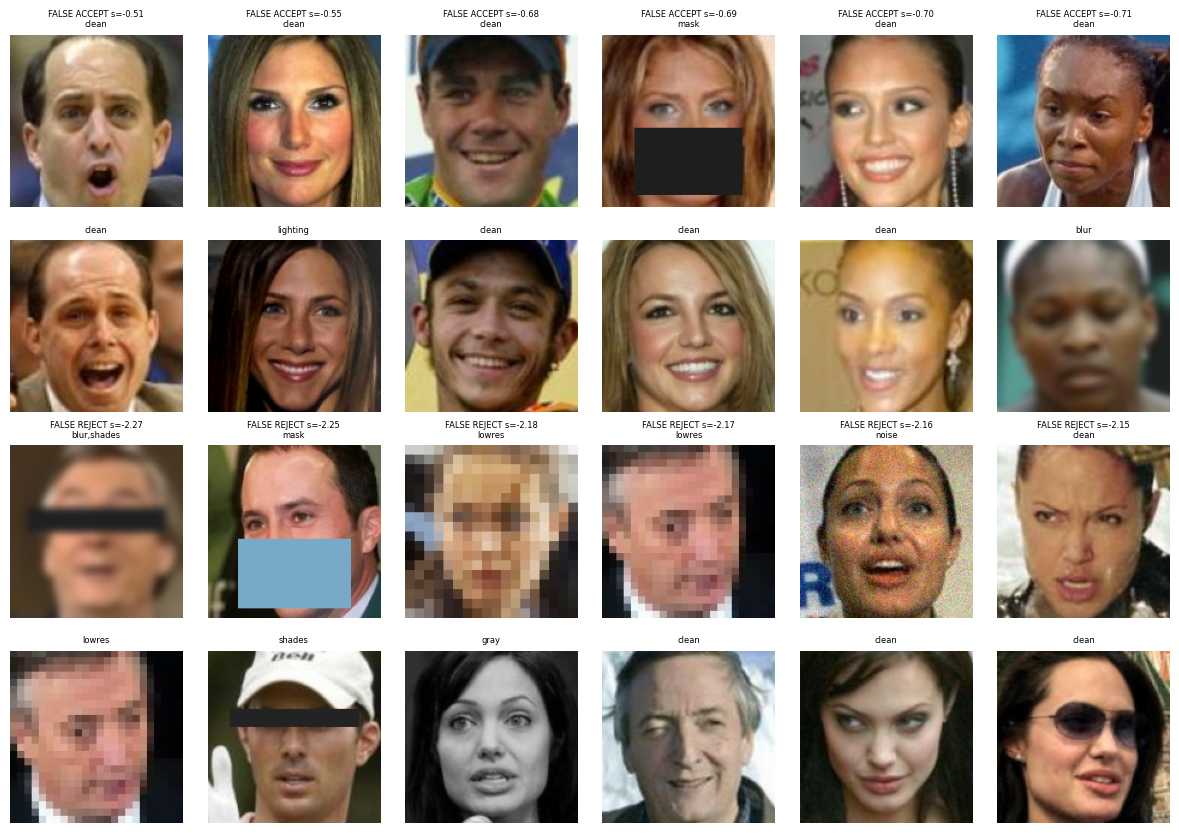

In [66]:
use_ = FINAL if FINAL in EMB else BEST; Et_f = EMB[use_][1]
rep = category_report(Et_f, RESULTS[use_]["tau_v"])
for k, v in rep.items(): print(f"{k:<20}" + "  ".join(f"{a}={b:.3f}" if isinstance(b, float) else f"{a}={b}" for a, b in v.items()))
show_results(["B5_margin0.3", "B6_cleanaug", use_])

show_failures = lambda name, k=6: gv.show_failures(D, EMB[name][1], k)
show_failures(use_)

**Answer Q8**

(a) …

(b) …

(c) …

(d) …

(e) …

In [67]:
# (b) one number supporting your mechanism
# Q8(b): how do the two score means move with degradation?  (unit vectors: cosine = 1 + score / 2)
E8 = l2n(np.asarray(EMB[FINAL][1], dtype=np.float64)); P8 = D.test.pairs; deg8 = D.test.flags > 0
nd8 = deg8[P8.i].astype(int) + deg8[P8.j].astype(int)
cos8 = (E8[P8.i] * E8[P8.j]).sum(1)
for c in (0, 1, 2):
    m = nd8 == c
    print(f"{c} degraded: mean cosine  same-person {cos8[m & (P8.y == 1)].mean():.3f}  |  different-people {cos8[m & (P8.y == 0)].mean():.3f}")
# , (c) your normalisation / fix, before-vs-after on val and test
# Q8(c): adaptive score normalisation (AS-norm, Auckenthaler et al. 2000) with a cohort of TRAINING embeddings;
#        the cohort size k is chosen on VAL.  Test is only used to report the result.
fin = members[0]                                                      # the trained E_final model (from the final cell)
C8 = l2n(embed(fin, Xtr, PLAN["size"]))                               # cohort = training photos (no val/test)
Ev8, Et8 = l2n(np.asarray(EMB[FINAL][0], np.float64)), l2n(np.asarray(EMB[FINAL][1], np.float64))
def cohort_stats(E, k):                                               # mean/std of each photo's k most similar cohort scores
    top = np.sort(E @ C8.T, 1)[:, -k:]
    return top.mean(1), top.std(1) + 1e-6
def asnorm(E, P, k):
    mu, sd = cohort_stats(E, k); s = (E[P.i] * E[P.j]).sum(1)
    return 0.5 * ((s - mu[P.i]) / sd[P.i] + (s - mu[P.j]) / sd[P.j])
raw = lambda E, P: (E[P.i] * E[P.j]).sum(1)
pi_t8 = D.meta.test_prevalence
def report(name, sv, st):
    thr = f1_sweep(sv, V.pairs.y, neg_weights(V.pairs.y, pi_t8))["best_thr"]          # threshold chosen on VAL
    print(f"{name:<22} val V-F1 {f1_at(sv, V.pairs.y, thr):.4f} | test V-F1 {f1_at(st, T.pairs.y, thr):.4f}"
          f" | test AUC {roc_metrics(st, T.pairs.y)['auc']:.4f}")
val_auc = {k: roc_metrics(asnorm(Ev8, V.pairs, k), V.pairs.y)["auc"] for k in (25, 100, 400, 1600, len(C8))}
k_best = max(val_auc, key=val_auc.get)
print("val AUC by cohort size k:", {k: round(a, 4) for k, a in val_auc.items()}, "-> k =", k_best)
report("before (raw scores)", raw(Ev8, V.pairs), raw(Et8, T.pairs))
report(f"after (AS-norm, k={k_best})", asnorm(Ev8, V.pairs, k_best), asnorm(Et8, T.pairs, k_best))

0 degraded: mean cosine  same-person 0.529  |  different-people 0.034
1 degraded: mean cosine  same-person 0.454  |  different-people 0.039
2 degraded: mean cosine  same-person 0.407  |  different-people 0.045
val AUC by cohort size k: {25: 0.9425, 100: 0.954, 400: 0.9549, 1600: 0.9538, 5638: 0.9529} -> k = 400
before (raw scores)    val V-F1 0.8510 | test V-F1 0.7944 | test AUC 0.9556
after (AS-norm, k=400) val V-F1 0.8819 | test V-F1 0.7795 | test AUC 0.9559


### Q9. Are the differences real?
The 12,000 test pairs come from only 336 people, so pairs that share a person are not independent. For two models $A$ and $B$ let $\Delta=\mathrm{AUC}_A-\mathrm{AUC}_B$ on the test pairs.

(a) Implement `boot_delta` and report the 95 % percentile bootstrap interval of $\Delta$ (1,000 resamples) when the **pairs** are resampled.
(b) Report the interval when the **people** are resampled: draw the identities with replacement and, for every draw, keep all pairs whose first photo belongs to that identity.
(c) The variance ratio $\mathrm{DE}=\mathrm{Var}_{(b)}(\Delta)/\mathrm{Var}_{(a)}(\Delta)$ estimates the design effect $\mathrm{DE}=1+(\bar m-1)\,\rho$, where $\bar m$ is the mean number of pairs per identity and $\rho$ the correlation between pairs of the same identity. For `B2_semihard` against `B3_hard`, compute $\bar m$, $\mathrm{DE}$, $\rho$ and the effective number of independent pairs $n_\text{eff}=n/\mathrm{DE}$.
(d) Using the intervals of (b): is `B2_semihard` better than `B3_hard`, is your final model better than `B2_semihard`, and can the margins of B5 be ranked?

In [68]:
def boot_delta(s_a, s_b, y, groups=None, n_boot=1000, seed=0):
    """Bootstrap of AUC(s_a) - AUC(s_b) on the same pairs (use your roc_metrics).
    groups=None: resample the pairs. Otherwise resample the distinct groups with replacement and take all pairs of every drawn group.
    Returns (low, high, deltas): the 2.5 and 97.5 percentiles and the array of bootstrap differences."""
    s_a, s_b, y = np.asarray(s_a, np.float64), np.asarray(s_b, np.float64), np.asarray(y)
    rng = np.random.default_rng(seed)
    n = len(y)
    if groups is not None:                                        # resample PEOPLE: list the pairs of each group once
        groups = np.asarray(groups)
        order = np.argsort(groups, kind="stable")
        _, start = np.unique(groups[order], return_index=True)
        members_g = np.split(order, start[1:])                    # pair indices of each distinct group
    deltas = np.empty(n_boot)
    for b in range(n_boot):
        if groups is None:
            idx = rng.integers(0, n, n)                           # n pairs drawn with replacement
        else:
            pick = rng.integers(0, len(members_g), len(members_g))    # groups drawn with replacement
            idx = np.concatenate([members_g[g] for g in pick])        # ...and ALL pairs of every drawn group
        deltas[b] = roc_metrics(s_a[idx], y[idx])["auc"] - roc_metrics(s_b[idx], y[idx])["auc"]
    low, high = np.percentile(deltas, [2.5, 97.5])
    return float(low), float(high), deltas

sc = lambda name: pair_scores(EMB[name][1], T.pairs.i, T.pairs.j)
y9, g9 = T.pairs.y, T.y[T.pairs.i]                            # label and identity of the first photo of every test pair
VAR = {}
print(f"{'A - B':<34}{'Delta AUC':>10}{'95% CI, pairs':>24}{'95% CI, people':>24}")
for a, b in (("B2_semihard", "B3_hard"), (FINAL, "B2_semihard"), ("B5_margin0.3", "B5_margin0.1")):
    d0 = roc_metrics(sc(a), y9)["auc"] - roc_metrics(sc(b), y9)["auc"]
    lo1, hi1, dp = boot_delta(sc(a), sc(b), y9)
    lo2, hi2, dg = boot_delta(sc(a), sc(b), y9, groups=g9)
    VAR[(a, b)] = (float(np.var(dp)), float(np.var(dg)))
    print(f"{a + ' - ' + b:<34}{d0:>10.4f}{f'[{lo1:.4f}, {hi1:.4f}]':>24}{f'[{lo2:.4f}, {hi2:.4f}]':>24}")
va, vb = VAR[("B2_semihard", "B3_hard")]                      # bootstrap variances: pairs (a), people (b)
m_bar = len(y9) / len(np.unique(g9))                          # mean number of test pairs per person
DE = vb / va                                                  # design effect = Var(people) / Var(pairs)
rho = (DE - 1) / (m_bar - 1)                                  # from DE = 1 + (m_bar - 1) * rho
n_eff = len(y9) / DE                                          # effective number of independent pairs
print(f"(c) m_bar = {m_bar} | DE = {DE} | rho = {rho} | n_eff = {n_eff}")

A - B                              Delta AUC           95% CI, pairs          95% CI, people
B2_semihard - B3_hard                 0.0279        [0.0235, 0.0324]        [0.0190, 0.0367]
E_final - B2_semihard                 0.0267        [0.0223, 0.0312]        [0.0185, 0.0347]
B5_margin0.3 - B5_margin0.1           0.0044       [-0.0028, 0.0117]       [-0.0058, 0.0143]
(c) m_bar = 35.714285714285715 | DE = 3.6771408124293163 | rho = 0.0771192826625729 | n_eff = 3263.4050780536077


**Answer Q9**

(a) …

(b) …

(c) …

(d) …

---
# Part 8. Use case: the entrance of a co-working space

Christophe manages the entrance of a co-working space and Aya is its data protection officer. They want to know whether the door can run on your model. The scenario below is generated from your AUBNET, so the numbers differ between students.

Design decisions (threshold, expected cost) use val. What actually happens at the door is measured on test. Do not tune on test.

In [69]:
SC = gd.make_scenario(AUBNET, D)
USE = FINAL if FINAL in RESULTS else BEST          # the model that runs the door
E_use_v, E_use_t = EMB[USE]
print(f"""Entrance scenario for {AUBNET}
  members enrolled (one clean ID photo each) : K = {SC['K']}
  entries per day                            : N = {SC['N']}
  share of entries by strangers              : u = {SC['u']:.0%}
  cost of a stranger / wrong-name admission  : ${SC['c_fa']:.0f}
  cost of sending a member to the front desk : ${SC['c_fr']:.0f}
  Aya's rule                                 : at most ONE stranger admitted per {SC['days']} days
  model in use                               : {USE}""")
scn = lambda split, ids, E: gx.scenario_outcomes(D, split, ids, E, open_set_decide)     # (predicted identity, d_min, true identity / -1)
S_val, S_test = scn("val", SC["val_ids"], E_use_v), scn("test", SC["test_ids"], E_use_t)
print("val probes: known", int((S_val[2] >= 0).sum()), "strangers", int((S_val[2] < 0).sum()), "| test probes: known", int((S_test[2] >= 0).sum()), "strangers", int((S_test[2] < 0).sum()))

Entrance scenario for wmh16
  members enrolled (one clean ID photo each) : K = 48
  entries per day                            : N = 2500
  share of entries by strangers              : u = 30%
  cost of a stranger / wrong-name admission  : $250
  cost of sending a member to the front desk : $5
  Aya's rule                                 : at most ONE stranger admitted per 30 days
  model in use                               : E_final
val probes: known 142 strangers 835 | test probes: known 183 strangers 2748


### 8.1 Outcomes and cost
At threshold $\tau$ a known probe is admitted correctly, admitted under the wrong name (an incident, cost $c_\text{fa}$), or sent to the front desk (cost $c_\text{fr}$). A stranger is admitted (cost $c_\text{fa}$) or turned away (no cost).

Implement `scenario_rates(dmin, pred_id, true_id, tau)`, returning `p_ok`, `p_wrong`, `p_rej` (over known probes) and `p_stranger` (over strangers), and `expected_daily_cost(rates, sc)`:
$$\text{cost per day}=N\Big[(1-u)\big(p_\text{wrong}\,c_\text{fa}+p_\text{rej}\,c_\text{fr}\big)+u\,p_\text{stranger}\,c_\text{fa}\Big],$$
with $N$ entries per day and stranger share $u$.

*Figure 8. The possible outcomes at the door and their costs.*

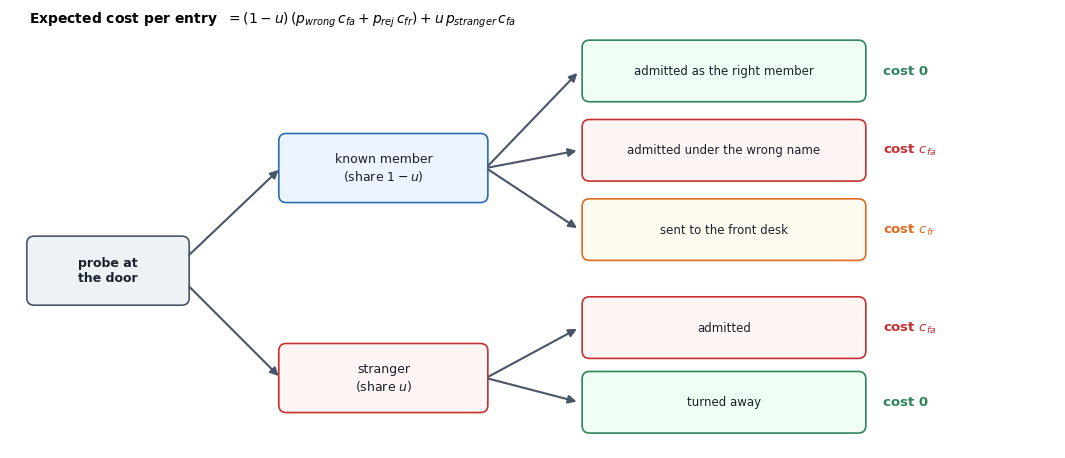

In [70]:
if "gf" in globals(): gf.fig_cost_tree()
else: print("Run the setup cell first: it loads the helper modules.")

In [71]:
def scenario_rates(dmin, pred_id, true_id, tau):
    dmin, pred_id, true_id = np.asarray(dmin, np.float64), np.asarray(pred_id), np.asarray(true_id)
    acc = dmin <= tau                                        # admitted at threshold tau
    known, unk = true_id >= 0, true_id < 0
    nk, nu = max(int(known.sum()), 1), max(int(unk.sum()), 1)
    return dict(p_ok=float((acc & known & (pred_id == true_id)).sum() / nk),     # member admitted, right name
                p_wrong=float((acc & known & (pred_id != true_id)).sum() / nk),  # member admitted, wrong name
                p_rej=float((~acc & known).sum() / nk),                          # member sent to the desk
                p_stranger=float((acc & unk).sum() / nu))                        # stranger admitted

def expected_daily_cost(r, sc):
    return float(sc["N"] * ((1 - sc["u"]) * (r["p_wrong"] * sc["c_fa"] + r["p_rej"] * sc["c_fr"])
                            + sc["u"] * r["p_stranger"] * sc["c_fa"]))

In [72]:
run_check("scenario", lambda: gk.check_scn(scenario_rates, expected_daily_cost))

✔ scenario


### 8.2 Operating points
On val, find (i) $\tau_\text{cost}$, which minimises the expected daily cost, (ii) $\tau_{F1}$, which maximises O-F1, and (iii) $\tau_\text{aya}$, the largest threshold with stranger FAR at most $\text{far}^*=1/(\text{days}\cdot N\cdot u)$ (at most one stranger admitted per 30 days). For each, report the expected cost on val, the realised cost on test, and a 95 % bootstrap interval of the test cost (`bootstrap_cost`: resample known probes and strangers separately, 500 times).

Which threshold would you ship, how far is the test cost from the val estimate, and what does the bootstrap not capture? (at most three sentences)

In [73]:
far_star = 1.0 / (SC["days"] * SC["N"] * SC["u"])   # <= one stranger admitted per `days` days
cands = np.unique(S_val[1])
val_costs = np.array([expected_daily_cost(scenario_rates(S_val[1], S_val[0], S_val[2], t), SC) for t in cands])
tau_cost = float(cands[int(np.argmin(val_costs))])                       # cheapest threshold on VAL
tau_f1 = best_open_set_threshold(S_val[1], S_val[0], S_val[2])[0]       # best O-F1 on VAL
tau_aya = float(dir_at_far(S_val[1], S_val[0], S_val[2], far_star)[1])  # largest tau with stranger FAR <= far_star on VAL

def bootstrap_cost(S, tau, sc, n=500, seed=0):
    """95% interval (2.5, 97.5 percentiles) of the expected daily cost, resampling known / stranger probes separately."""
    pred, dmin, true = (np.asarray(a) for a in S)
    acc = dmin <= tau
    kn, un = np.flatnonzero(true >= 0), np.flatnonzero(true < 0)
    wrong = (acc & (pred != true))[kn].astype(float)        # per known probe: admitted under a wrong name
    rej = (~acc)[kn].astype(float)                           # per known probe: sent to the desk
    fa = acc[un].astype(float)                               # per stranger: admitted
    rng = np.random.default_rng(seed)
    costs = np.empty(n)
    for b in range(n):
        ik = rng.integers(0, len(kn), len(kn)); iu = rng.integers(0, len(un), len(un))
        costs[b] = expected_daily_cost(dict(p_wrong=wrong[ik].mean(), p_rej=rej[ik].mean(), p_stranger=fa[iu].mean()), sc)
    lo, hi = np.percentile(costs, [2.5, 97.5])
    return float(lo), float(hi)

print(f"far_star = {far_star}")
for nm, t in (("tau_cost", tau_cost), ("tau_F1", tau_f1), ("tau_aya", tau_aya)):
    cv = expected_daily_cost(scenario_rates(S_val[1], S_val[0], S_val[2], t), SC)
    rt = scenario_rates(S_test[1], S_test[0], S_test[2], t); ct = expected_daily_cost(rt, SC); lo, hi = bootstrap_cost(S_test, t, SC)
    print(f"{nm:<9} tau={t:7.3f} | val cost ${cv:9.0f}/day | TEST cost ${ct:9.0f}/day  95% CI [{lo:.0f}, {hi:.0f}] | admitted strangers {rt['p_stranger']:.3%}  wrong-name {rt['p_wrong']:.3%}  desk {rt['p_rej']:.3%}")

far_star = 4.4444444444444447e-05
tau_cost  tau=  0.770 | val cost $     7311/day | TEST cost $     7559/day  95% CI [6513, 8587] | admitted strangers 1.201%  wrong-name 0.000%  desk 60.656%
tau_F1    tau=  0.933 | val cost $    16996/day | TEST cost $    21321/day  95% CI [14311, 31016] | admitted strangers 5.531%  wrong-name 1.639%  desk 43.169%
tau_aya   tau=  0.717 | val cost $     7579/day | TEST cost $     6945/day  95% CI [6078, 7799] | admitted strangers 0.619%  wrong-name 0.000%  desk 66.120%


**Answer 8.2**

(thresholds and costs) …

(choice) …

### 8.3 Is Aya's rule measurable?
Report (i) $\text{far}^*$ for your scenario, (ii) the smallest FAR your test strangers can resolve, (iii) the number of stranger probes needed to demonstrate $\text{far}^*$ with 95 % confidence when no false accept is observed (rule of three), and (iv) the DIR at $\text{far}^*$ on val and on test with the val threshold. Can you promise Aya her rule? (at most two sentences)

In [74]:
n_unk_test = int((S_test[2] < 0).sum())
res_far = 1.0 / n_unk_test                                   # smallest nonzero FAR the test strangers can show: 1 false accept among all of them
probes_needed = int(np.ceil(3.0 / far_star))                 # rule of three: 0 false accepts in n probes -> 95% upper bound 3/n
dir_val, tau_r = dir_at_far(S_val[1], S_val[0], S_val[2], far_star)
rt = scenario_rates(S_test[1], S_test[0], S_test[2], tau_r); dir_test = rt["p_ok"]     # DIR on test at tau_r: correct accepts / known probes
print(f"far_star={far_star:.2e} | resolvable FAR on test = {res_far} | probes needed = {probes_needed} (have {n_unk_test}) | DIR val {dir_val:.3f}, test {dir_test}")

far_star=4.44e-05 | resolvable FAR on test = 0.000363901018922853 | probes needed = 67500 (have 2748) | DIR val 0.134, test 0.33879781420765026


**Answer 8.3**

((i)–(iv)) …

(conclusion) …

### 8.4 Doubling the membership
Keep $\tau_\text{cost}$ and estimate the expected daily cost for galleries of size $K$ and $2K$ drawn at random from all test identities (`gd.sample_gallery`, 20 galleries each; use the maximum available if $2K$ exceeds the number of test identities). Report $\text{cost}(2K)/\text{cost}(K)$ and explain why it is, or is not, close to 2 (at most two sentences).

In [75]:
def cost_at_K(Kg, tau, n_rep=20, seed=0):
    """mean, std of the expected daily cost over n_rep random test galleries of size Kg at threshold tau"""
    rng = np.random.default_rng(seed)
    costs = []
    for _ in range(n_rep):
        g = gd.sample_gallery(D, "test", Kg, rng)                         # Kg random test identities as members
        pred, dmin, true = scn("test", g.gal_y, E_use_t)                  # same door code as the scenario
        costs.append(expected_daily_cost(scenario_rates(dmin, pred, true, tau), SC))
    return float(np.mean(costs)), float(np.std(costs))
K1, K2 = SC["K"], min(2 * SC["K"], T.n_ids)
c1, c2 = cost_at_K(K1, tau_cost), cost_at_K(K2, tau_cost)
print(f"K={K1}: ${c1[0]:.0f}±{c1[1]:.0f}/day | K={K2}: ${c2[0]:.0f}±{c2[1]:.0f}/day | ratio {c2[0] / c1[0]:.2f}")

K=48: $10489±3312/day | K=96: $14014±3628/day | ratio 1.34


**Answer 8.4**

(costs and ratio) …

(why) …

### 8.5 Recommendation
Four bullet points for Christophe and Aya, in plain language: the decision (ship, pilot with a fallback such as a PIN or a desk check, or do not ship); three numbers from your scenario that support it; two non-technical risks (for example consent and retention of biometric data, demographic bias that LFW cannot measure, photo spoofing, members rejected every day); one condition that would change the decision.

**Answer 8.5**

- Decision: …
- Numbers: …
- Risks: …
- Condition: …

---
# Part 9. Submission

State how you used AI tools (one sentence, or "none"), then run the export cell. Submit the notebook with all outputs, `submission.npz` and `submission_token.json`.

In [76]:
AI_USED = "Claude opus5.5 for writing and debugging the code; all written answers are mine."     # e.g. "ChatGPT for the plotting helpers; Claude for debugging pairwise_sq_dist; all reasoning answers are mine"
assert AI_USED.strip(), "write one sentence about how you used AI tools (or 'none')"

In [77]:
assert FINAL in RESULTS and FINAL in EMB, "run the final challenge model (E_final) first"
Ev_s, Et_s = EMB[FINAL]; rf = RESULTS[FINAL]
np.savez_compressed(os.path.join(WORK, "submission.npz"), E_val=Ev_s.astype(np.float32), E_test=Et_s.astype(np.float32),
                    tau_v=rf["tau_v"], tau_o=rf["tau_o"], aubnet=AUBNET.strip().lower(), fp=FP, smoke=bool(SMOKE))
tok = dict(aubnet=AUBNET.strip().lower(), fp=FP, smoke=bool(SMOKE), gpu=gt.gpu_name(), torch=torch.__version__, numpy=np.__version__, python=sys.version.split()[0], checks=CHECKS,
           challenge_steps=CHAL_LOG[FINAL]["steps"], challenge_images=CHAL_LOG[FINAL]["images"], budget_images=int(CH_IMAGES), peak_gb=CHAL_LOG[FINAL]["peak_gb"], ai=AI_USED,
           scenario={k: SC[k] for k in ("K", "u", "N", "c_fa", "c_fr")}, emb_sha=gd.sha(Et_s.astype(np.float32)),
           results={n: {k: round(float(v), 4) for k, v in RESULTS[n].items() if k in ("V_F1", "O_F1", "S", "AUC", "EER", "tau_v", "tau_o")}
                    for n in ("A_softmax", BEST, "C_binary_head", FINAL) if n in RESULTS})
tok["token"] = gd.sha(json.dumps(tok, sort_keys=True))
json.dump(tok, open(os.path.join(WORK, "submission_token.json"), "w"), indent=1)
import shutil; json.dump(tok, open("submission_token.json", "w"), indent=1); shutil.copy(os.path.join(WORK, "submission.npz"), "submission.npz")
print(json.dumps({k: tok[k] for k in ("aubnet", "challenge_steps", "peak_gb", "results")}, indent=1))
print("token:", tok["token"][:24], "…")
bad = [k for k, v in CHECKS.items() if not v]
print("\nchecks failed:", bad or "none", "| SMOKE run:", SMOKE, "| final run within budget:", tok["challenge_images"] <= CH_IMAGES * 1.0001)
print("Submit this notebook together with:", os.path.abspath("submission.npz"), "and", os.path.abspath("submission_token.json"))

{
 "aubnet": "wmh16",
 "challenge_steps": 4000,
 "peak_gb": 6.98,
 "results": {
  "A_softmax": {
   "V_F1": 0.6256,
   "AUC": 0.8744,
   "EER": 0.2036,
   "O_F1": 0.2412,
   "S": 0.4334,
   "tau_v": -1.6764,
   "tau_o": 1.2178
  },
  "B2_semihard": {
   "V_F1": 0.72,
   "AUC": 0.9289,
   "EER": 0.1458,
   "O_F1": 0.3288,
   "S": 0.5244,
   "tau_v": -1.3756,
   "tau_o": 0.942
  },
  "C_binary_head": {
   "V_F1": 0.6765,
   "AUC": 0.9053,
   "EER": 0.1649,
   "O_F1": 0.134,
   "S": 0.4052,
   "tau_v": 0.0946,
   "tau_o": 0.3324
  },
  "E_final": {
   "V_F1": 0.7944,
   "AUC": 0.9556,
   "EER": 0.1115,
   "O_F1": 0.4517,
   "S": 0.6231,
   "tau_v": -1.3786,
   "tau_o": 0.9707
  }
 }
}
token: 9040ef53bb1a0d7f5ad825b0 …

checks failed: none | SMOKE run: False | final run within budget: True
Submit this notebook together with: /content/submission.npz and /content/submission_token.json


In [78]:
LEDGER.summary()

run                                  steps  peakGB   gpu
A_softmax                             2400    4.24   NVIDIA RTX PRO 6000 Blackwell Server Edition
B1_random                             3400    3.51   NVIDIA RTX PRO 6000 Blackwell Server Edition
B2_semihard                           3400    3.69   NVIDIA RTX PRO 6000 Blackwell Server Edition
B3_hard                               3400    3.88   NVIDIA RTX PRO 6000 Blackwell Server Edition
B4_unnormalized                       1400    4.06   NVIDIA RTX PRO 6000 Blackwell Server Edition
B5_margin0.1                          1400    4.06   NVIDIA RTX PRO 6000 Blackwell Server Edition
B5_margin0.3                          1400    4.06   NVIDIA RTX PRO 6000 Blackwell Server Edition
B5_margin0.9                          1400    4.06   NVIDIA RTX PRO 6000 Blackwell Server Edition
B6_cleanaug                           1400    4.06   NVIDIA RTX PRO 6000 Blackwell Server Edition
D1_hard_noisy                         3400    4.06   NVIDIA R